# Optimise Models 
Threshold adjustment

## 1. Import Libraries

In [5]:
import os
import pandas as pd

from config_models import OUTPUT_DIR
from config_optimisation import (
    GROUP_COUNT_COLS,
    CONFUSION_COUNT_COLS,
    
)
from optimisation_helpers import (
    load_model_data,
    make_output_dir,
    adjust_thresholds_in_subgroups,
    save_with_sdc,
    plot_confusion_matrices,
)

In [6]:
print(os.listdir(OUTPUT_DIR))

['test_confusion_matrices.csv', 'subgroup_confusion_matrices.csv', 'cv_results_hgb.csv', 'test_subgroup_data.csv.gz', 'test_data.csv.gz', 'train_subgroup_data.csv.gz', 'subgroup_test_performance.csv', 'subgroup_specific_models', 'train_predictions.csv.gz', 'cv_results_lr.csv', 'train_data.csv.gz', 'best_params.json', 'cv_summary.csv', 'cv_results_xgb.csv', 'test_performance.csv', 'cv_results_rf.csv', 'best_params.csv', 'test_predictions.csv.gz', 'optimisation']


## 2. Settings

In [7]:
OPTIMISATION_METHOD = "threshold_adjustment"
OPTIMISATION_DIR = make_output_dir(OPTIMISATION_METHOD)

## 3. Load Data

In [8]:
data = load_model_data()

train_subgroups = data["train_subgroups"]
test_subgroups = data["test_subgroups"]

train_predictions = pd.read_csv(os.path.join(OUTPUT_DIR, "train_predictions.csv.gz"))
test_predictions = pd.read_csv(os.path.join(OUTPUT_DIR, "test_predictions.csv.gz"))

print("Training predictions:", train_predictions.shape)
print("Test predictions:", test_predictions.shape)

Training predictions: (4000, 6)
Test predictions: (1000, 10)


 ## 4. Find thresholds and evaluate in subgroups 

In [9]:
subgroup_performance = adjust_thresholds_in_subgroups(
    train_predictions=train_predictions,
    test_predictions=test_predictions,
    train_subgroups=train_subgroups,
    test_subgroups=test_subgroups,
)

print("Rows:", len(subgroup_performance))
print("Subgroups skipped:", subgroup_performance["skip_reason"].notna().sum())

Rows: 324
Subgroups skipped: 24


## 5. Save

In [10]:
subgroup_performance_df = save_with_sdc(
    subgroup_performance,
    os.path.join(OPTIMISATION_DIR, "subgroup_test_performance.csv"),
    count_cols=GROUP_COUNT_COLS + CONFUSION_COUNT_COLS,
    release_exact=True,
)

print("Saved results to:", OPTIMISATION_DIR)

Saved results to: /Users/cu20932/Documents/Work/reducehf/output/models/optimisation/threshold_adjustment


## 6. Check

In [11]:
display(
    subgroup_performance_df[
        [
            "model",
            "subgroup_variable",
            "subgroup_level",
            "n_test",
            "threshold",
            "auc",
            "recall",
            "precision",
            "skip_reason",
        ]
    ].head(20)
)

,model,subgroup_variable,subgroup_level,n_test,threshold,auc,recall,precision,skip_reason
0,lr,age_band,50-54,83,0.419170,0.481221,0.774648,0.846154,None
1,lr,age_band,100+,164,0.429046,0.621311,0.726562,0.815789,None
2,lr,age_band,75-79,63,0.405788,0.675385,0.940000,0.783333,None
3,lr,age_band,60-64,64,0.405159,0.548185,0.765957,0.720000,None
4,lr,age_band,<45,13,0.465348,0.700000,0.875000,0.777778,None
5,lr,age_band,45-49,80,0.418085,0.601562,0.750000,0.813559,None
6,lr,age_band,70-74,78,0.421307,0.510081,0.774194,0.813559,None
7,lr,age_band,90-94,74,0.425898,0.577554,0.836066,0.836066,None
8,lr,age_band,95-99,76,0.425044,0.688645,0.761905,0.842105,None
9,lr,age_band,55-59,70,0.418214,0.484480,0.807018,0.807018,None


## 7. Plot Confusion Matrices

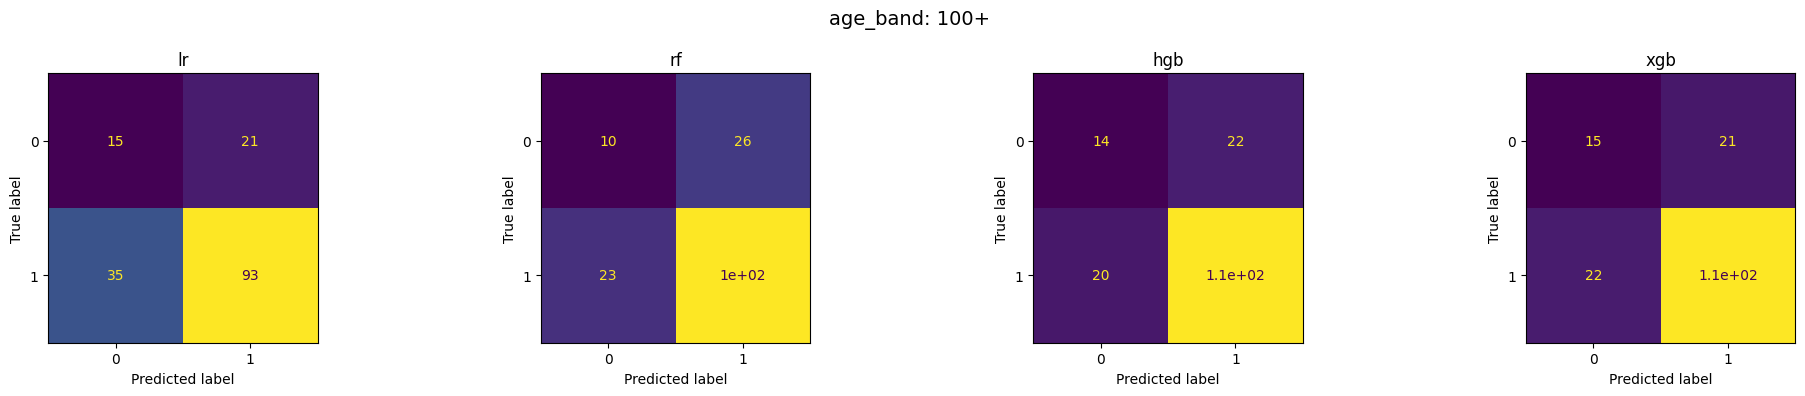

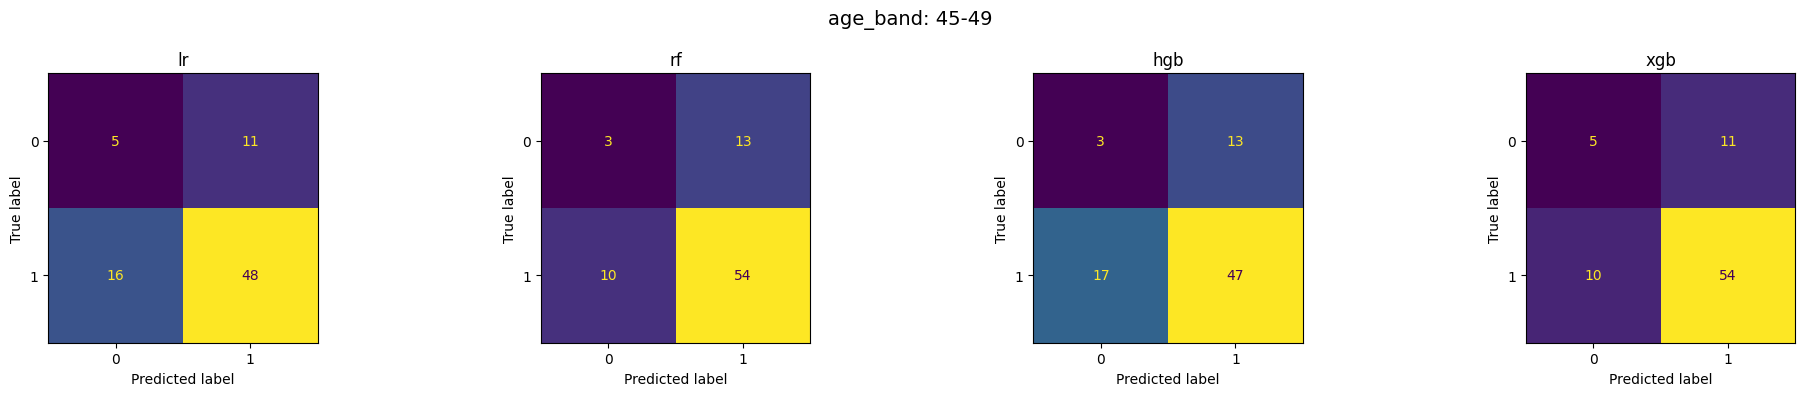

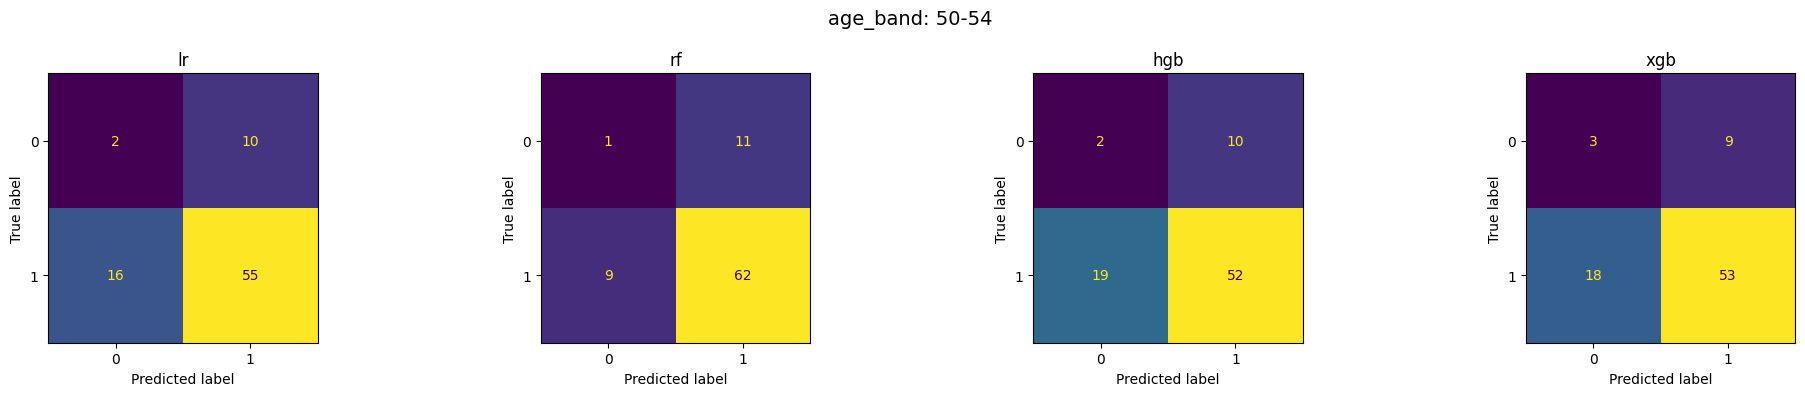

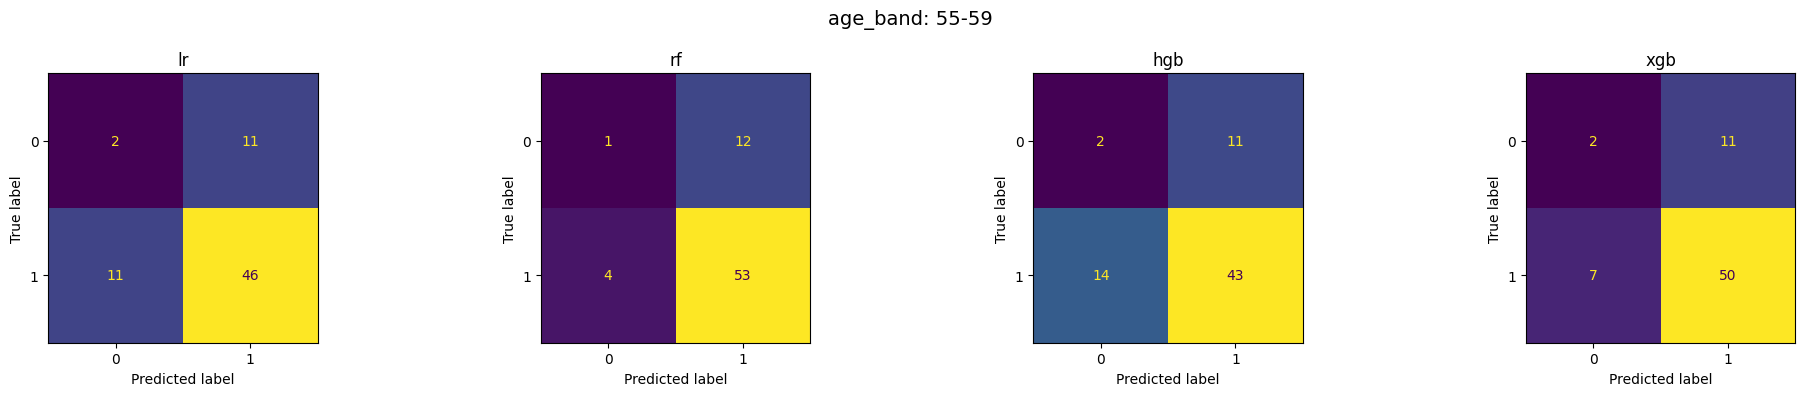

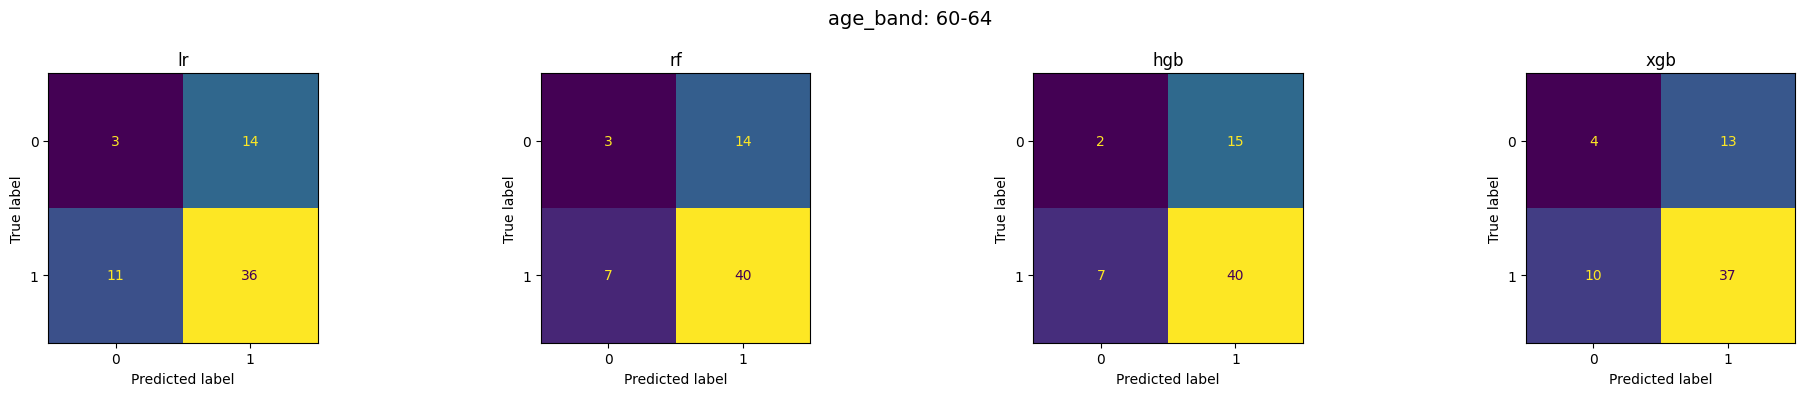

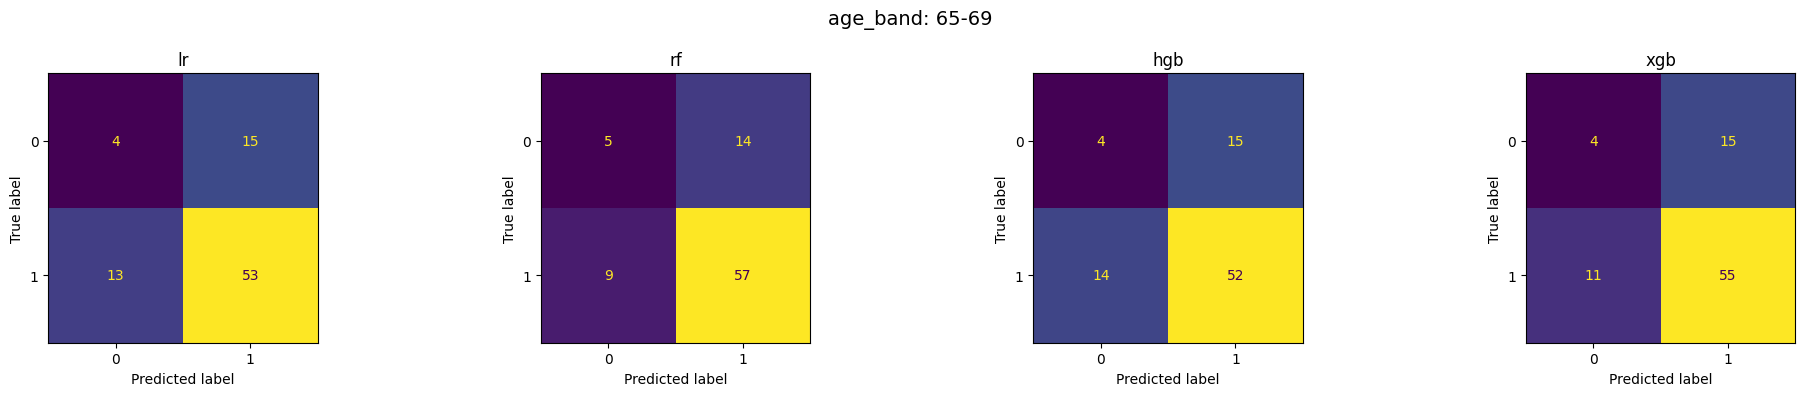

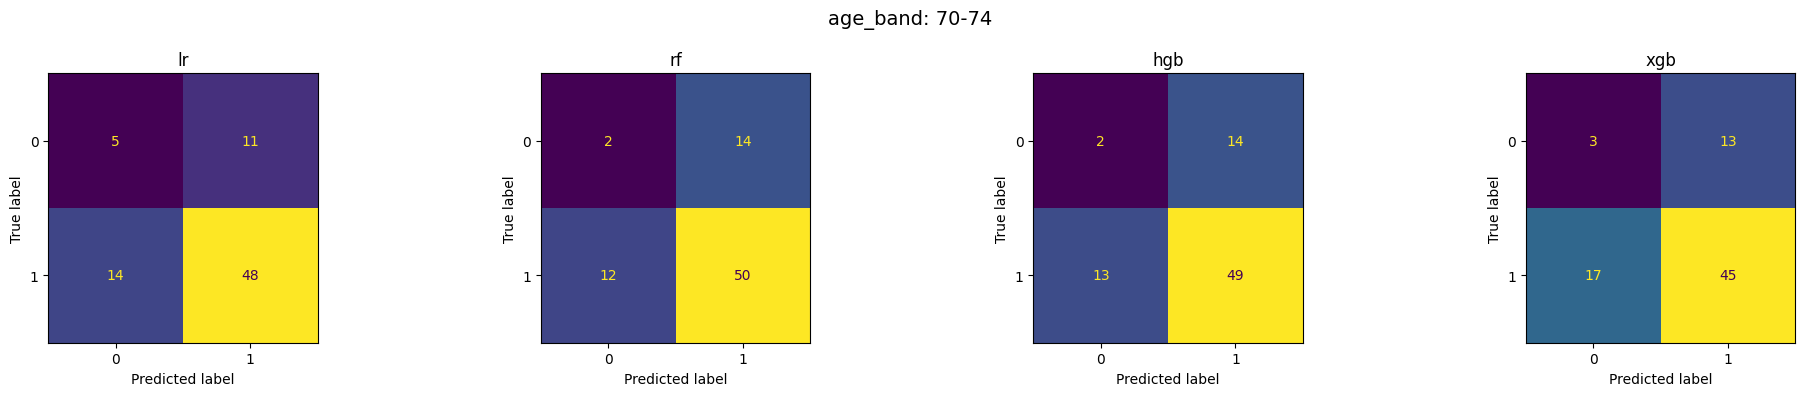

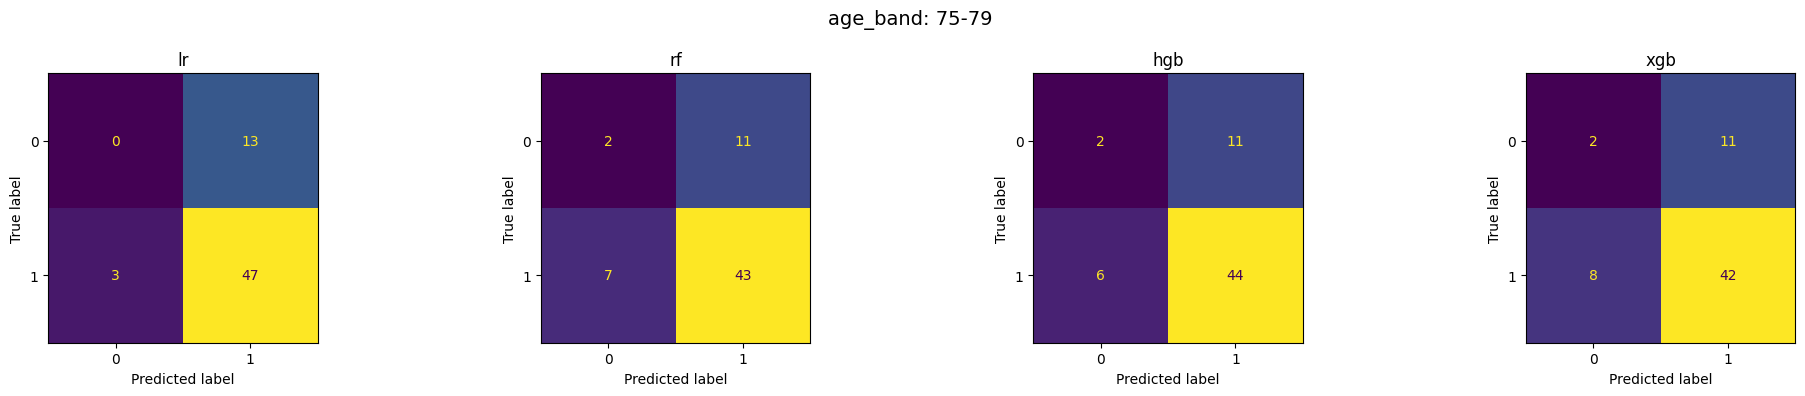

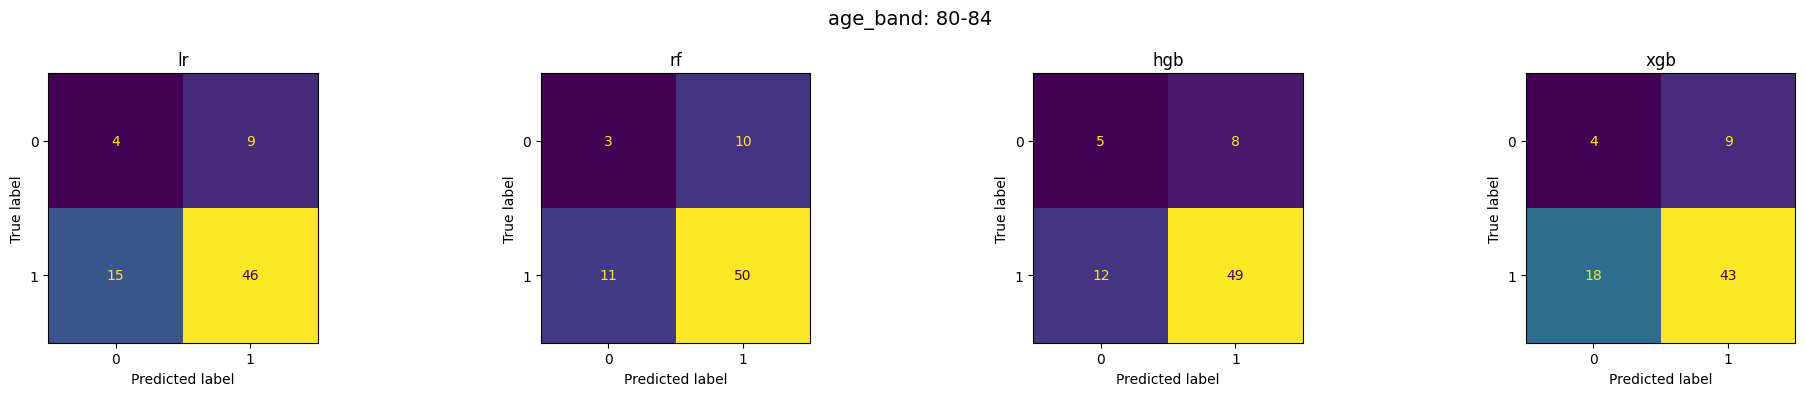

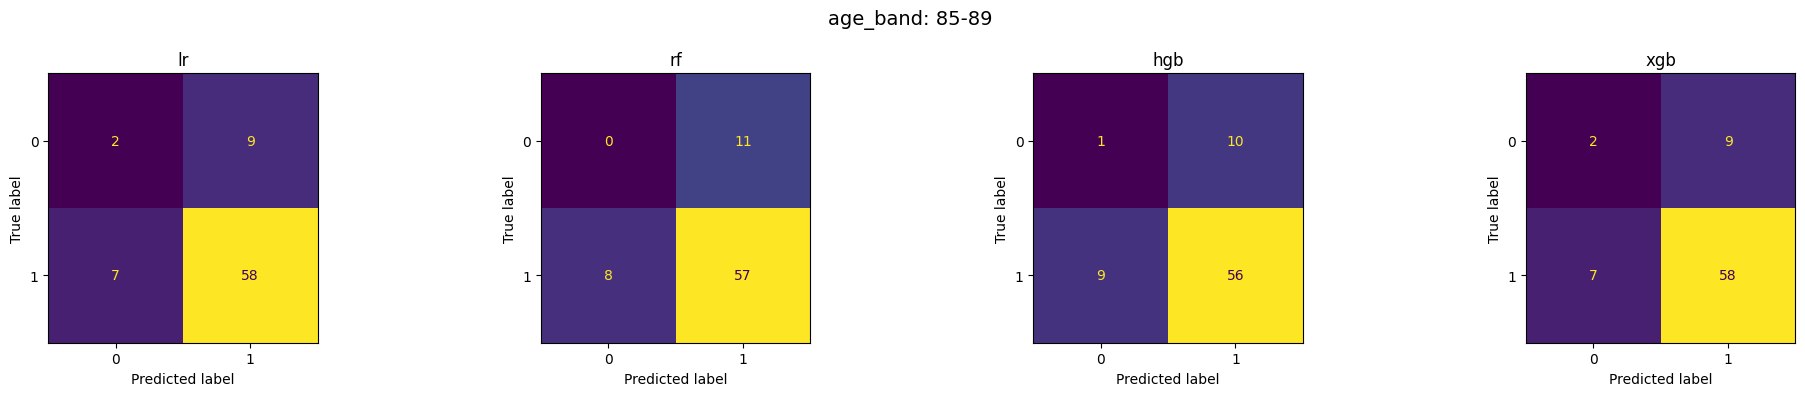

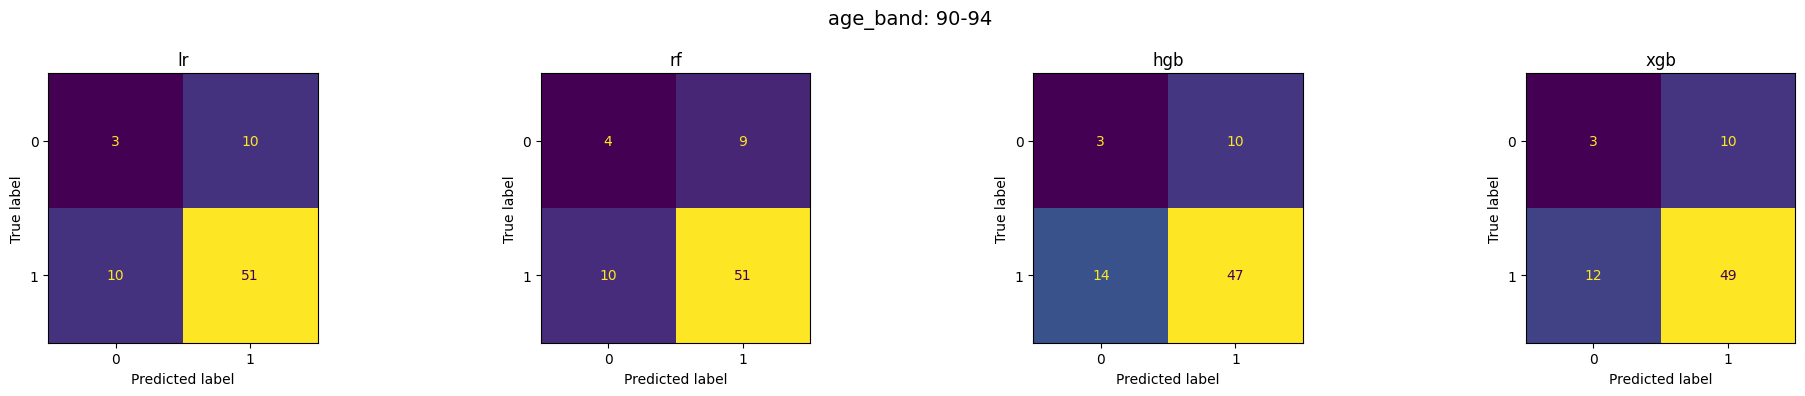

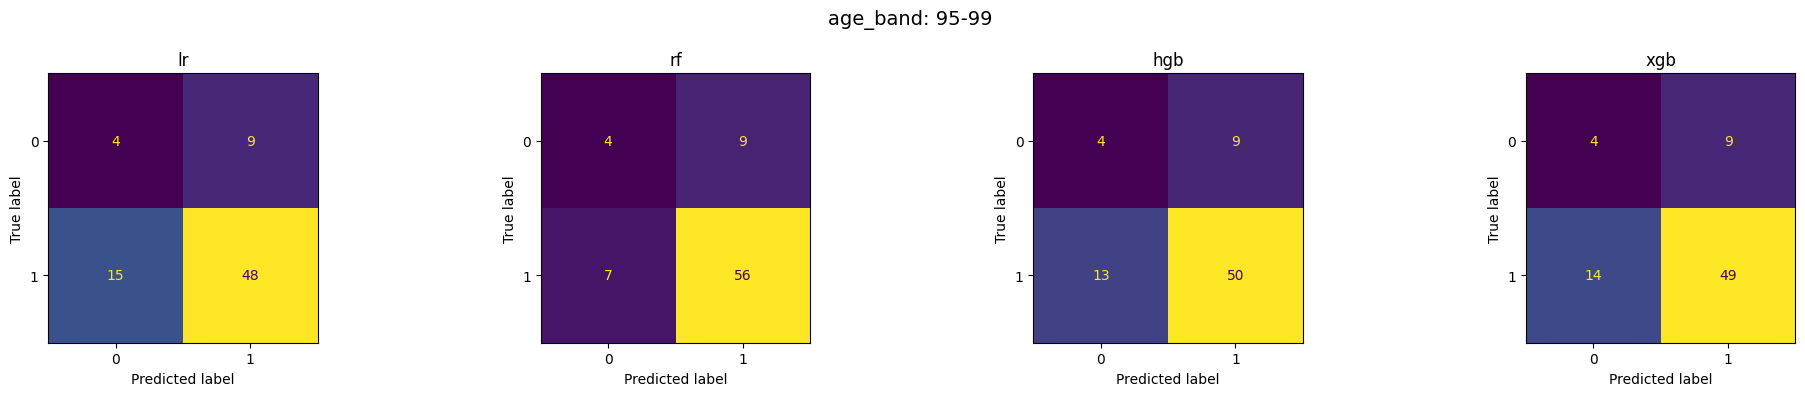

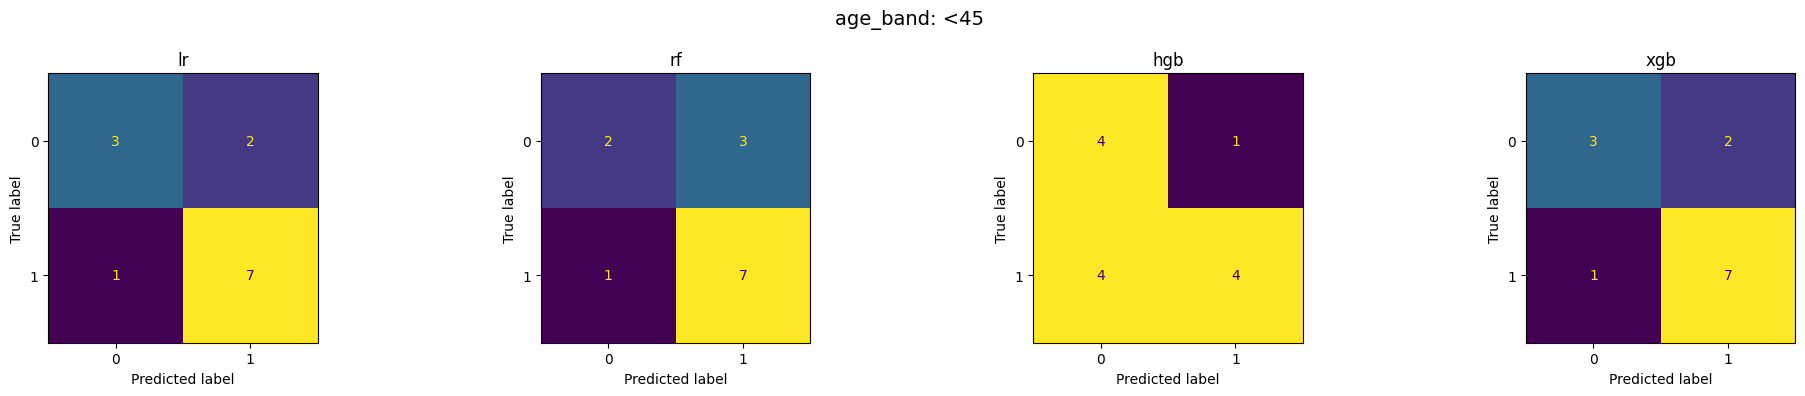

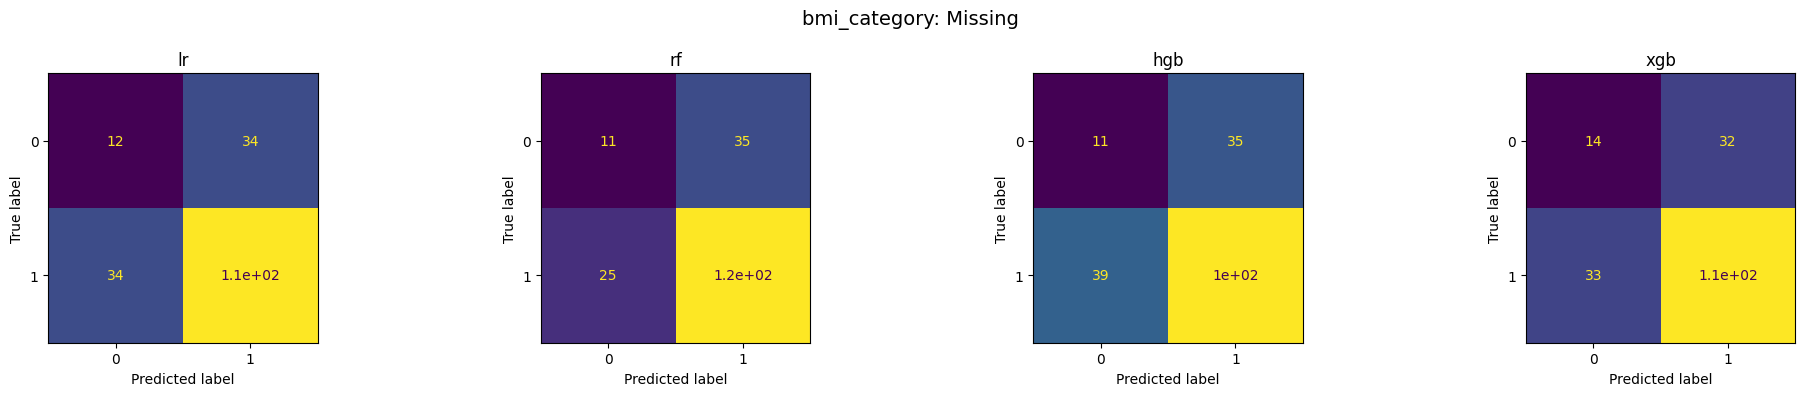

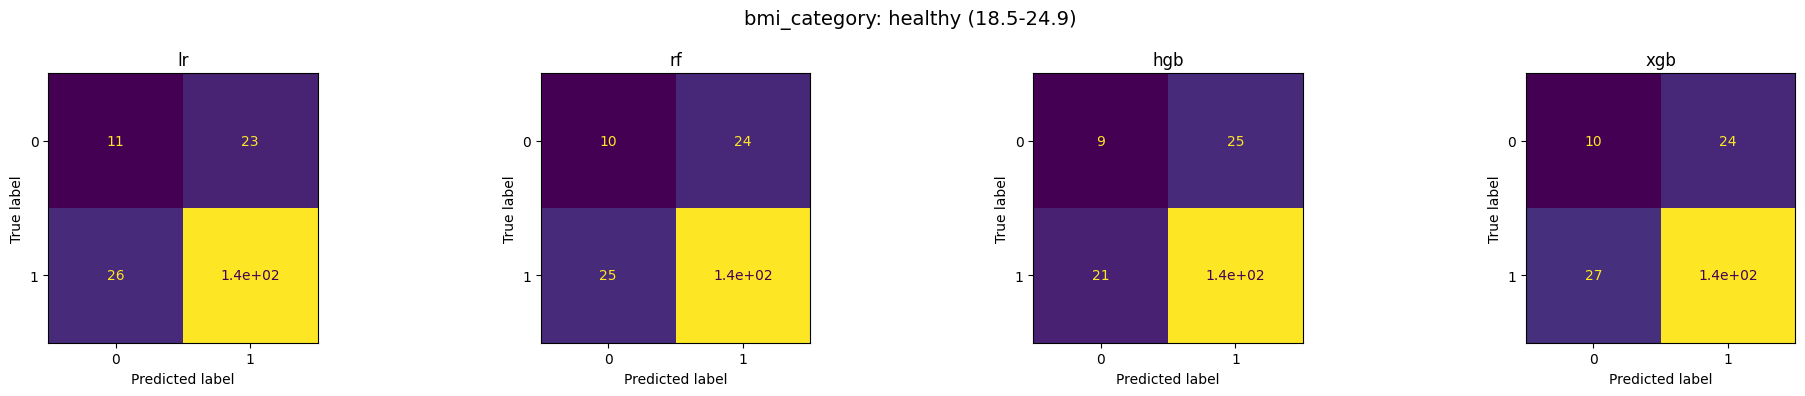

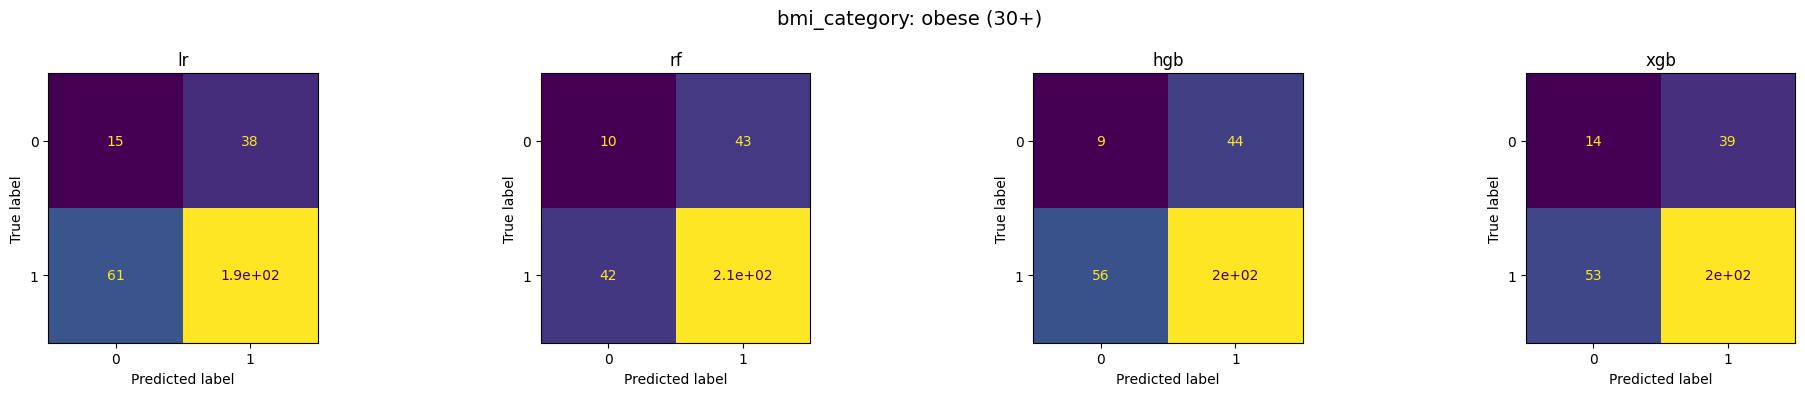

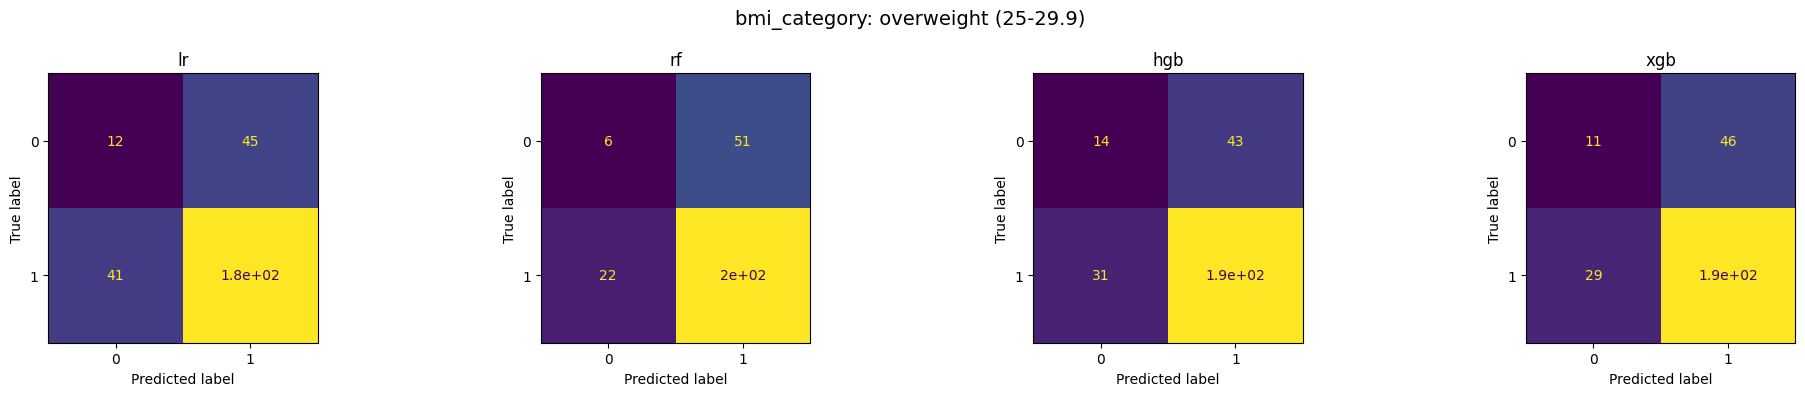

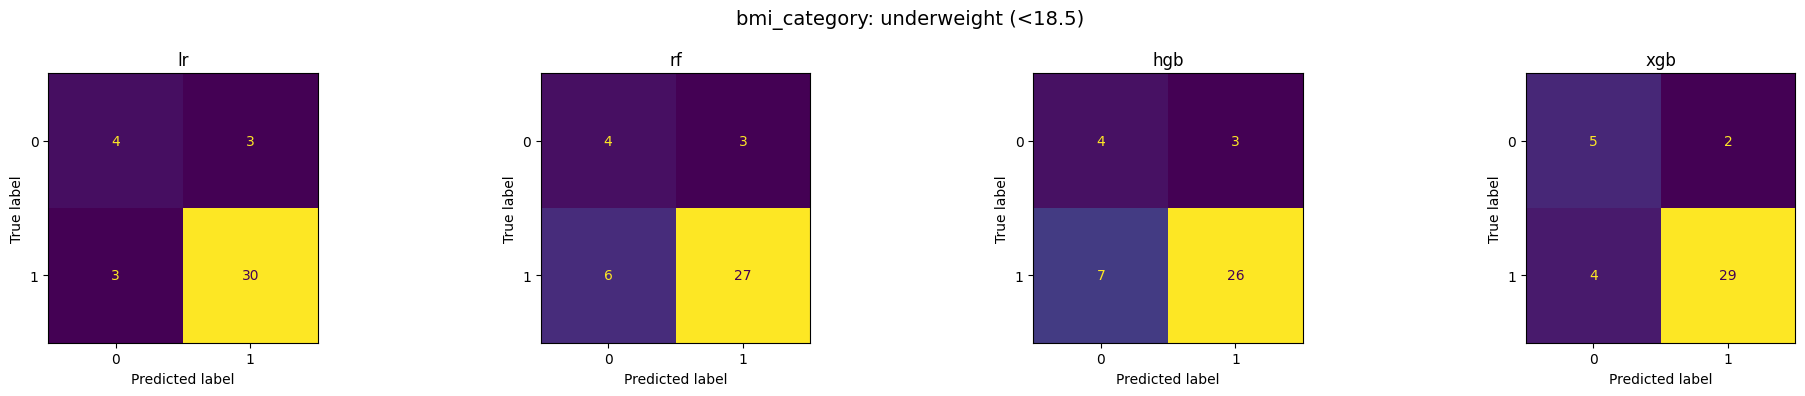

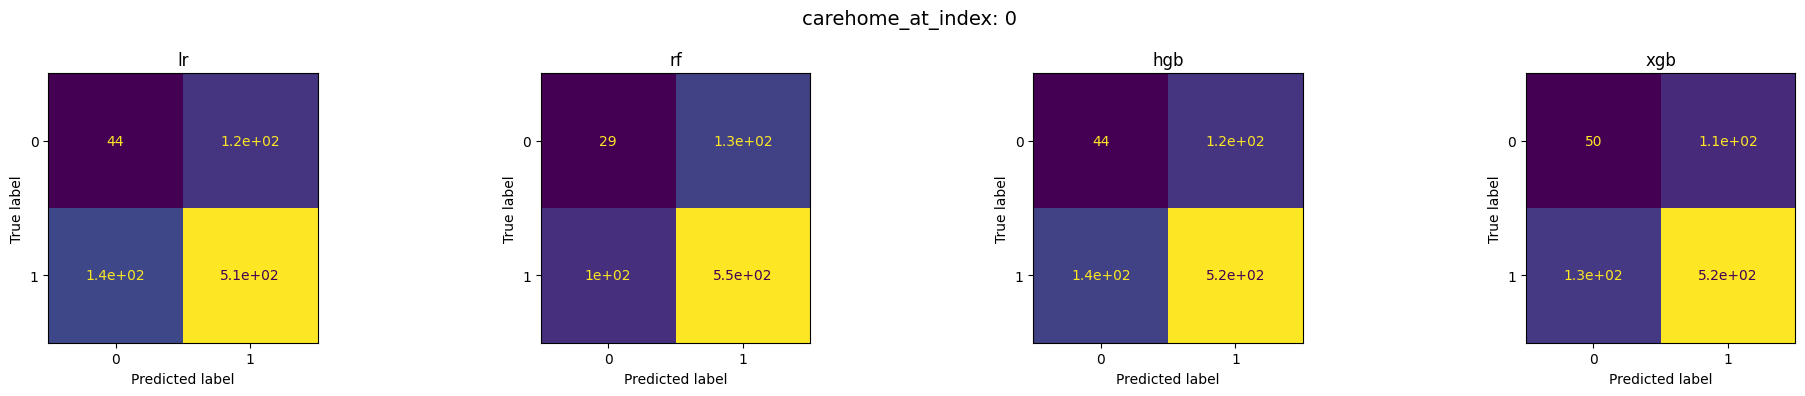

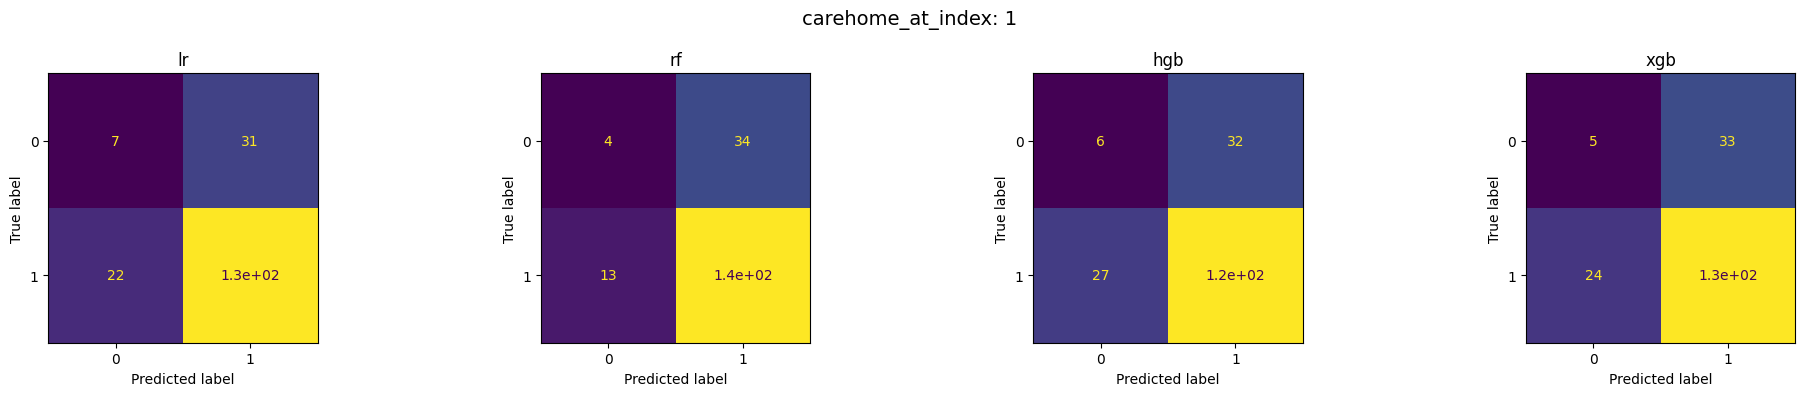

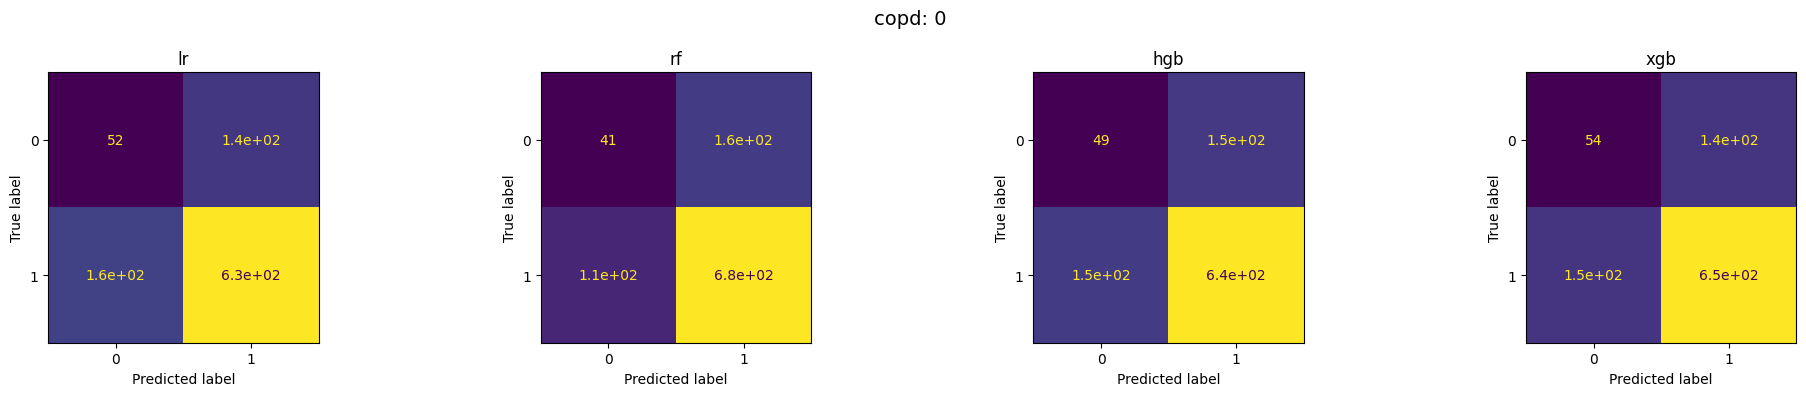

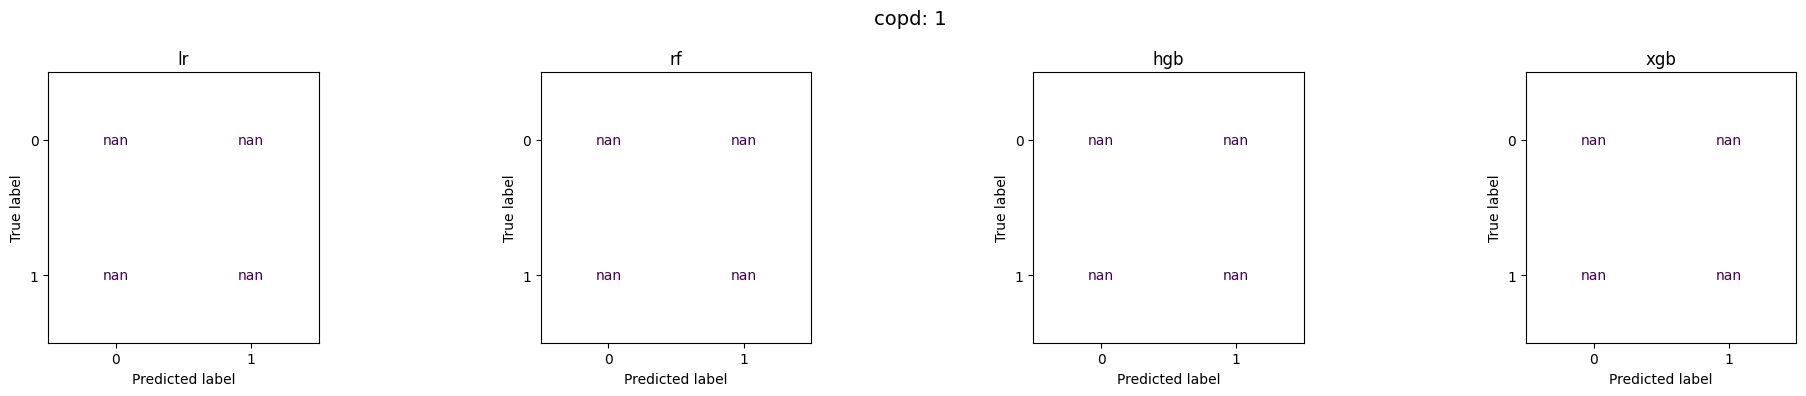

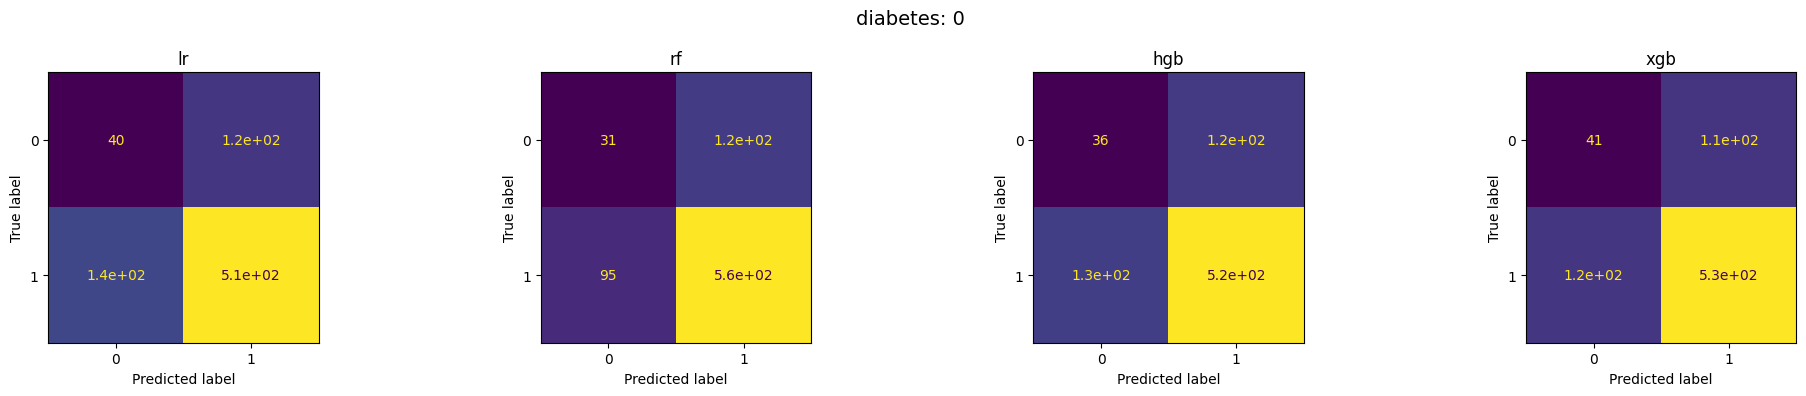

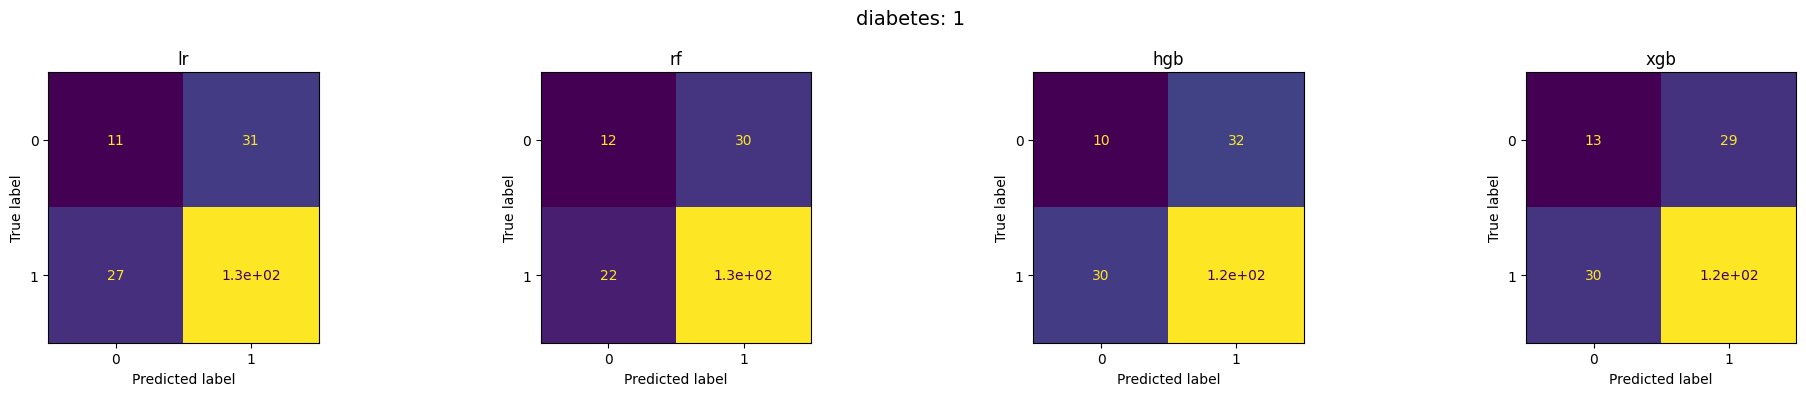

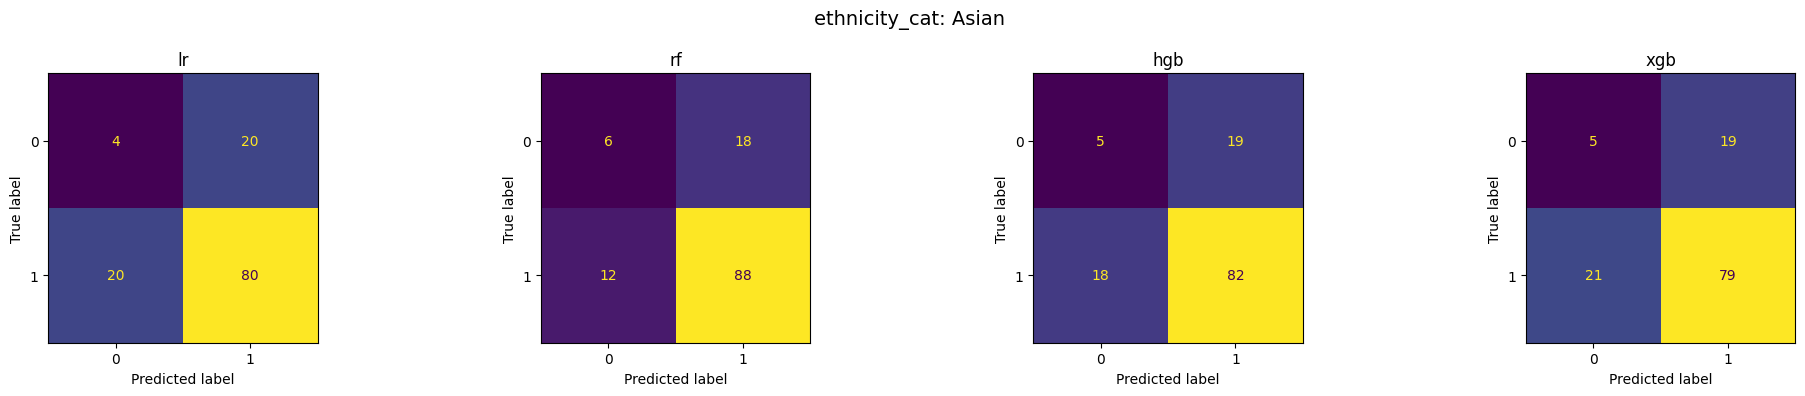

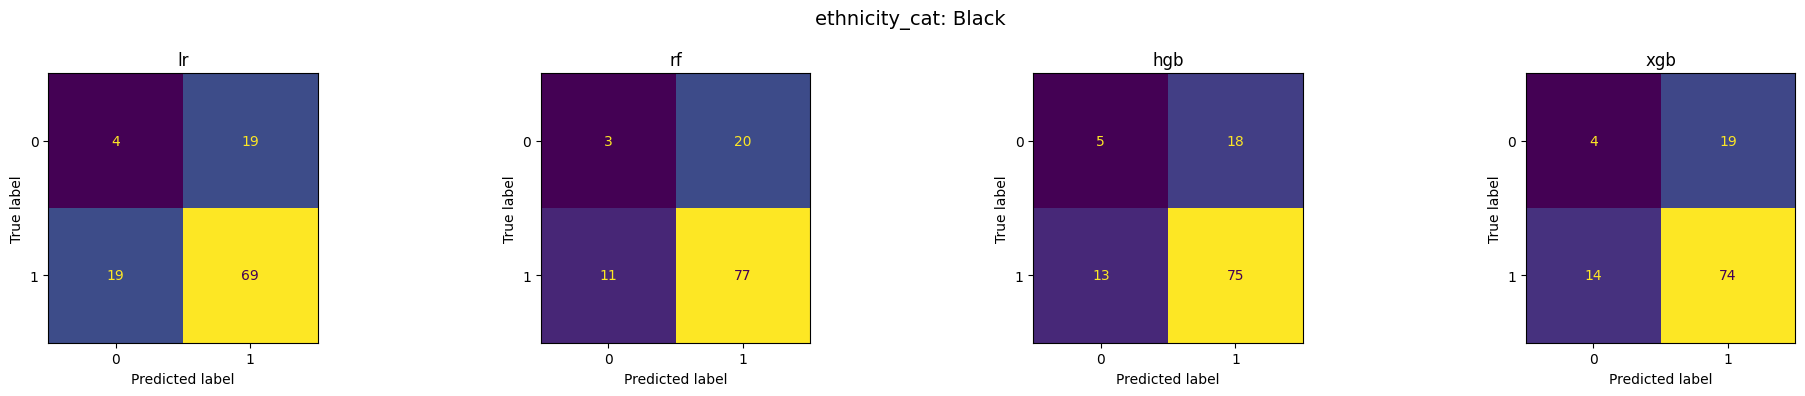

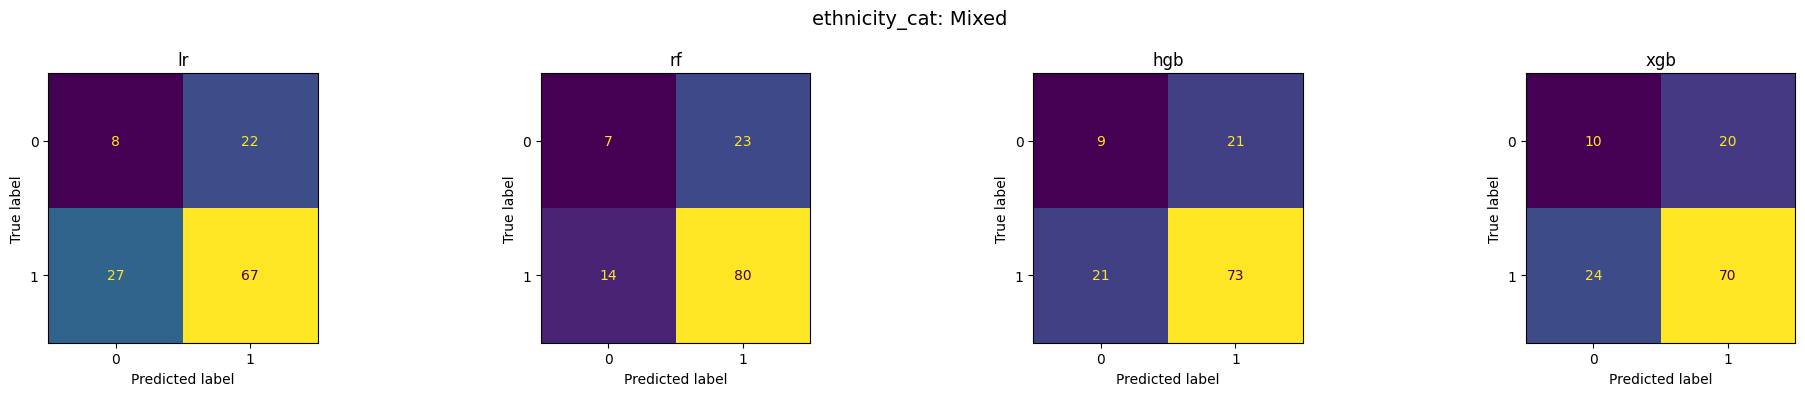

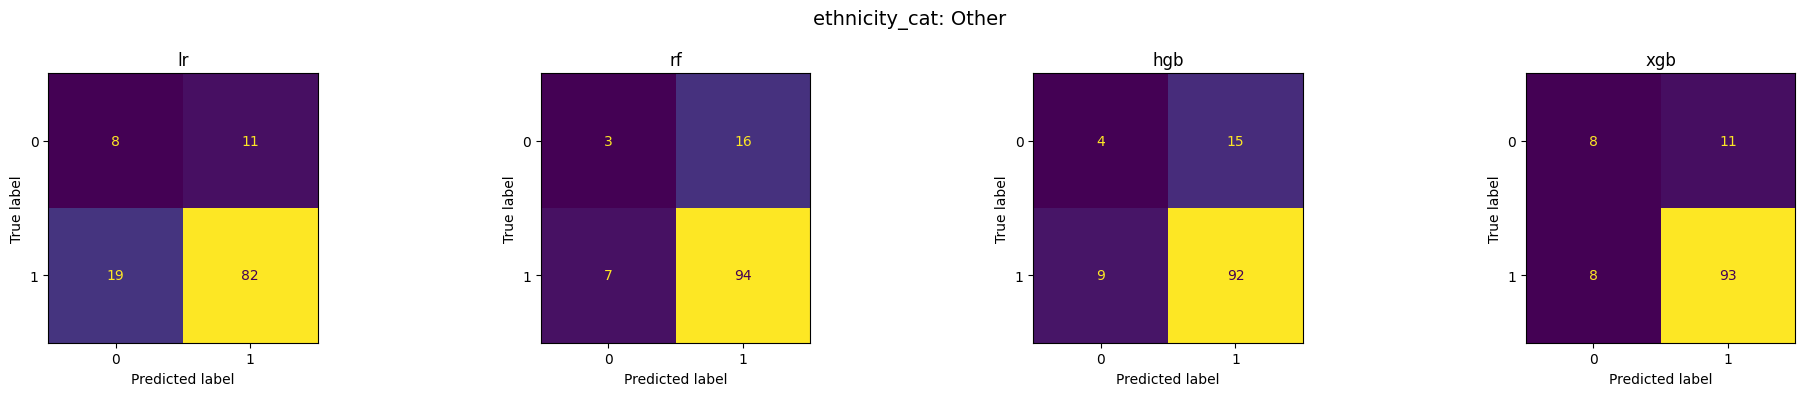

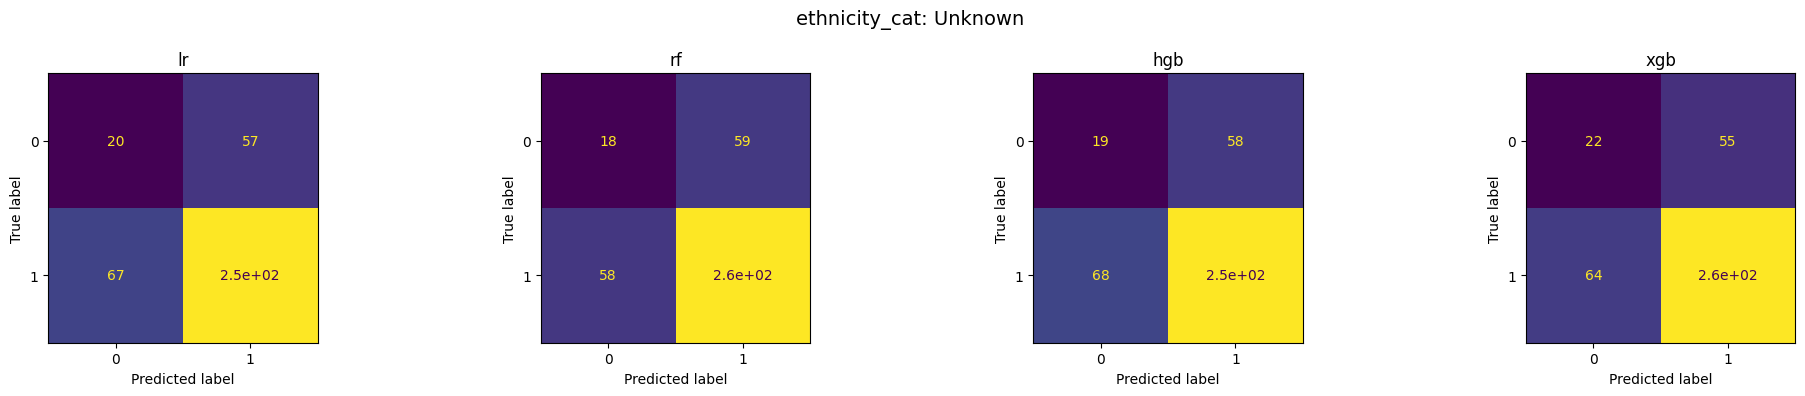

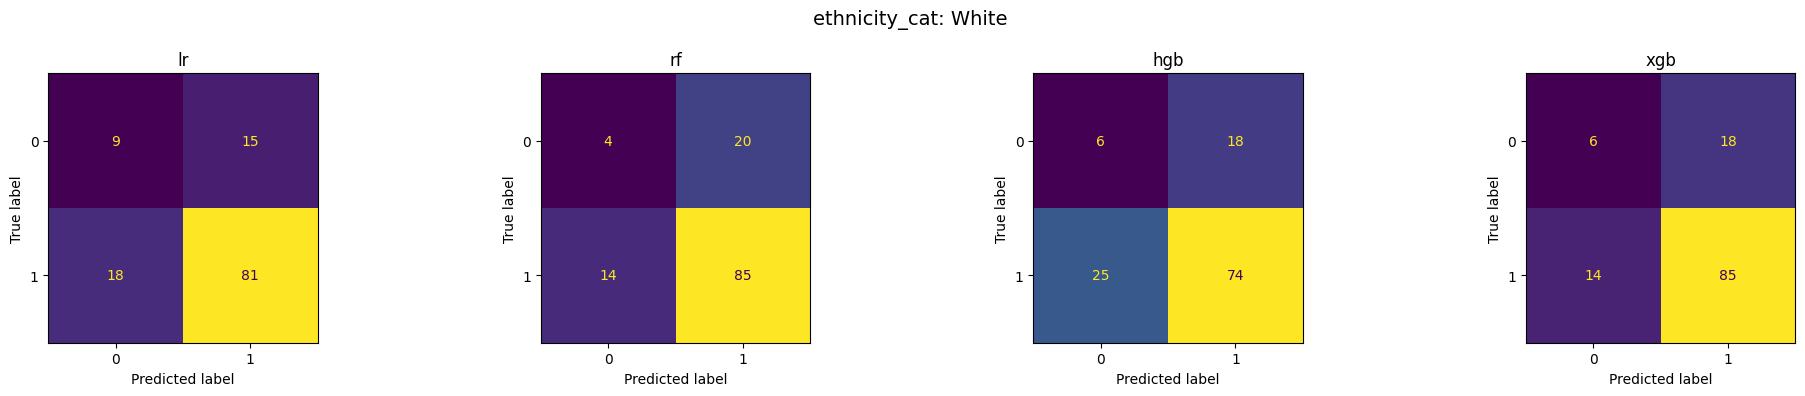

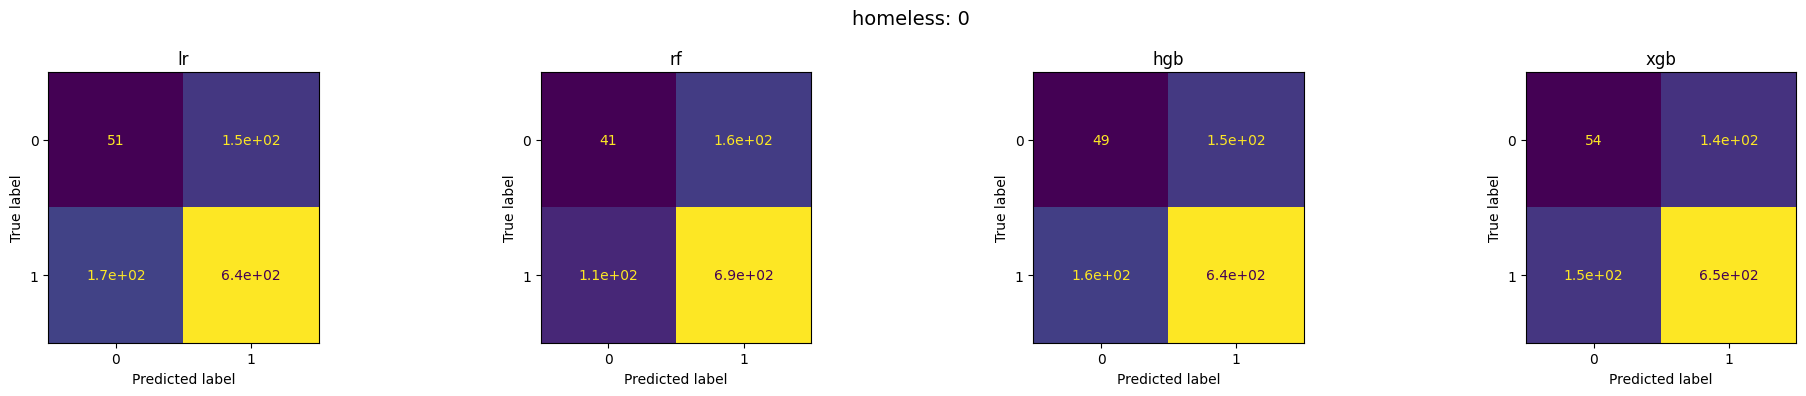

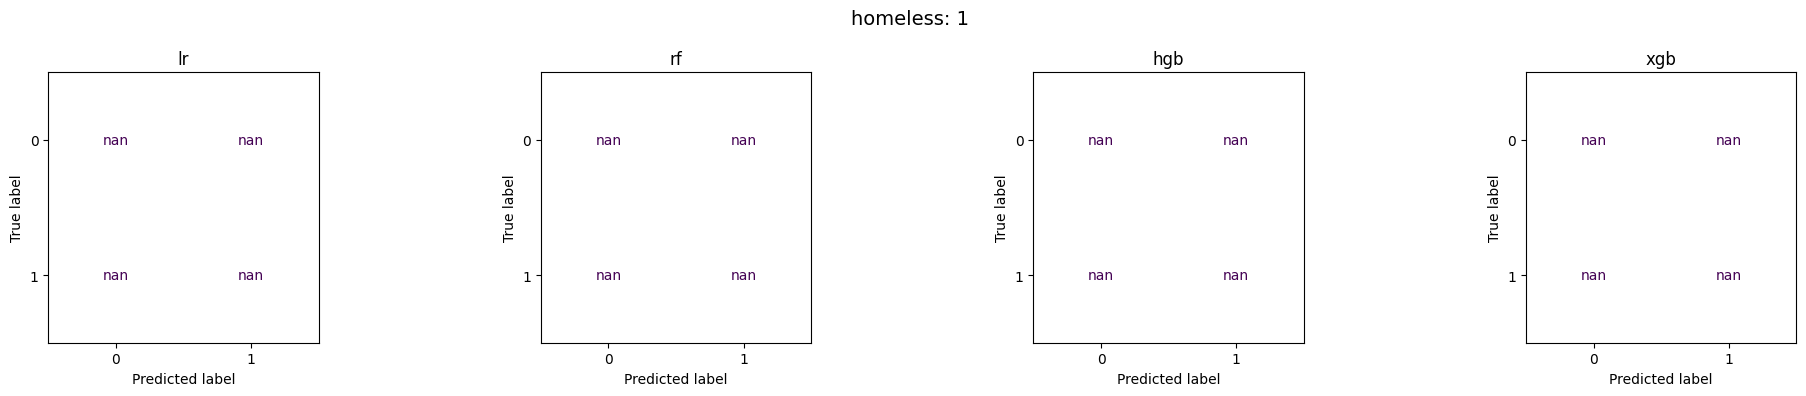

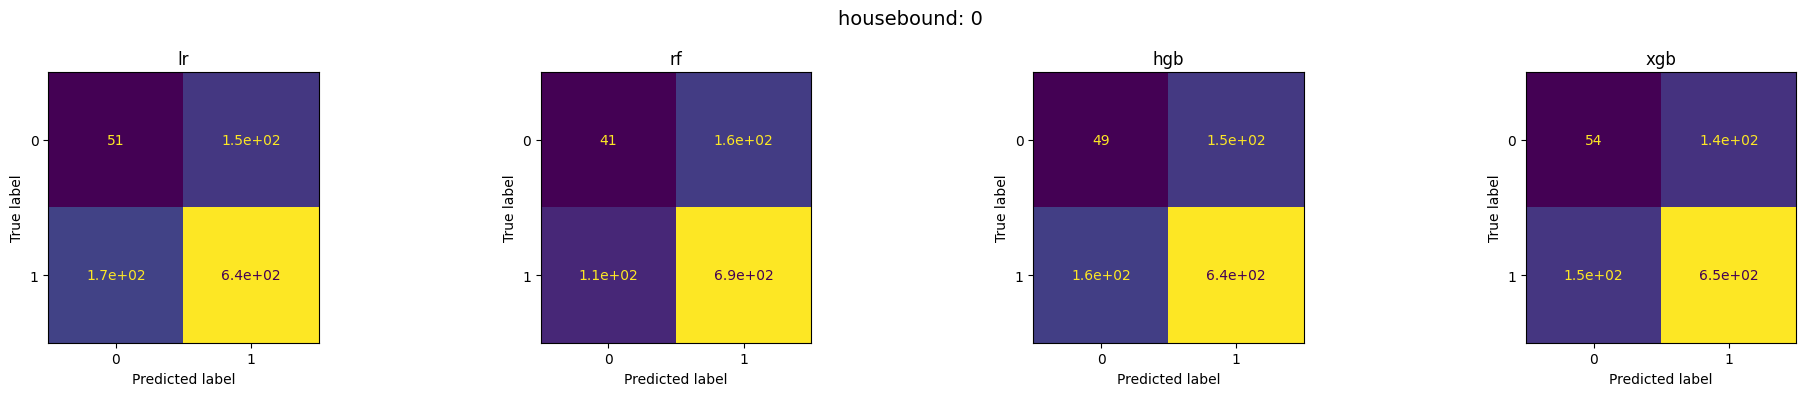

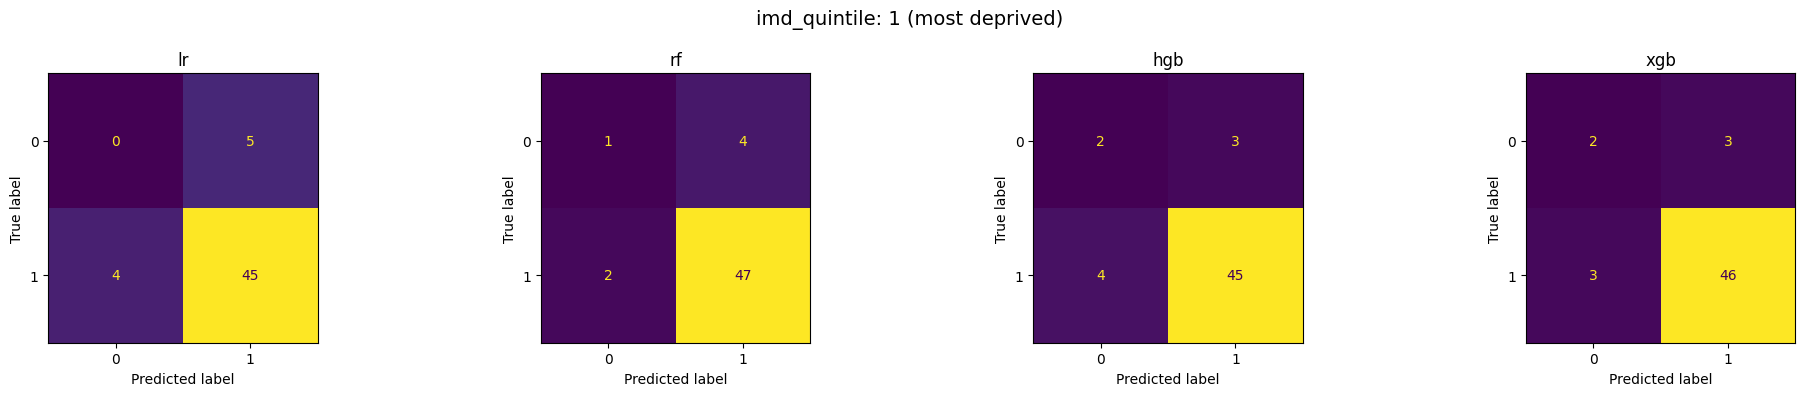

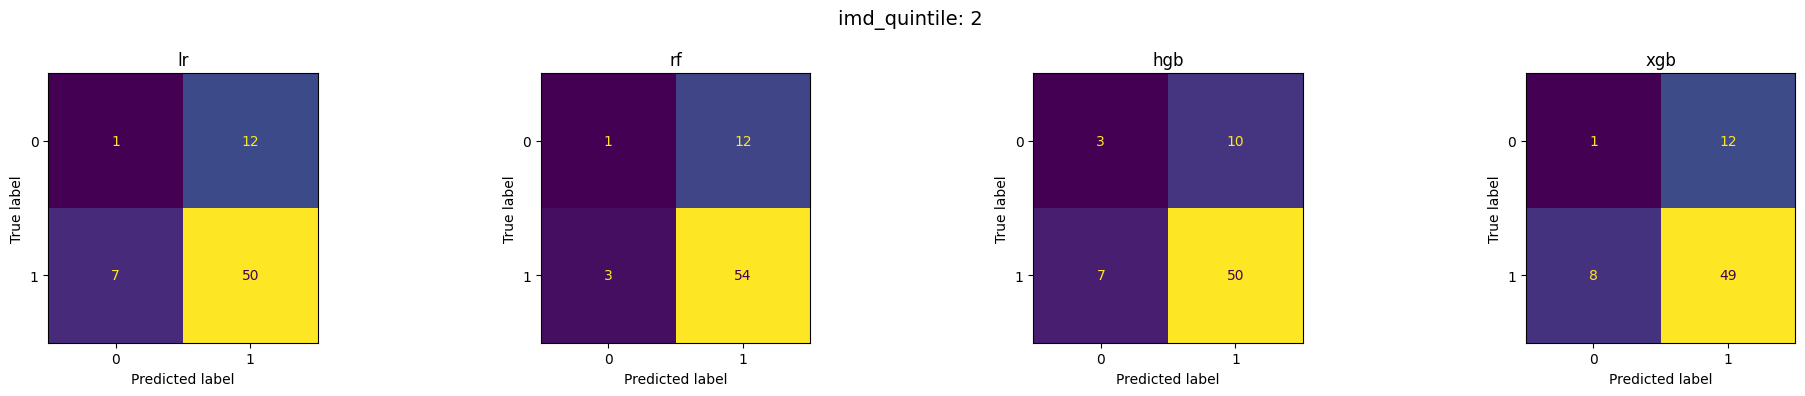

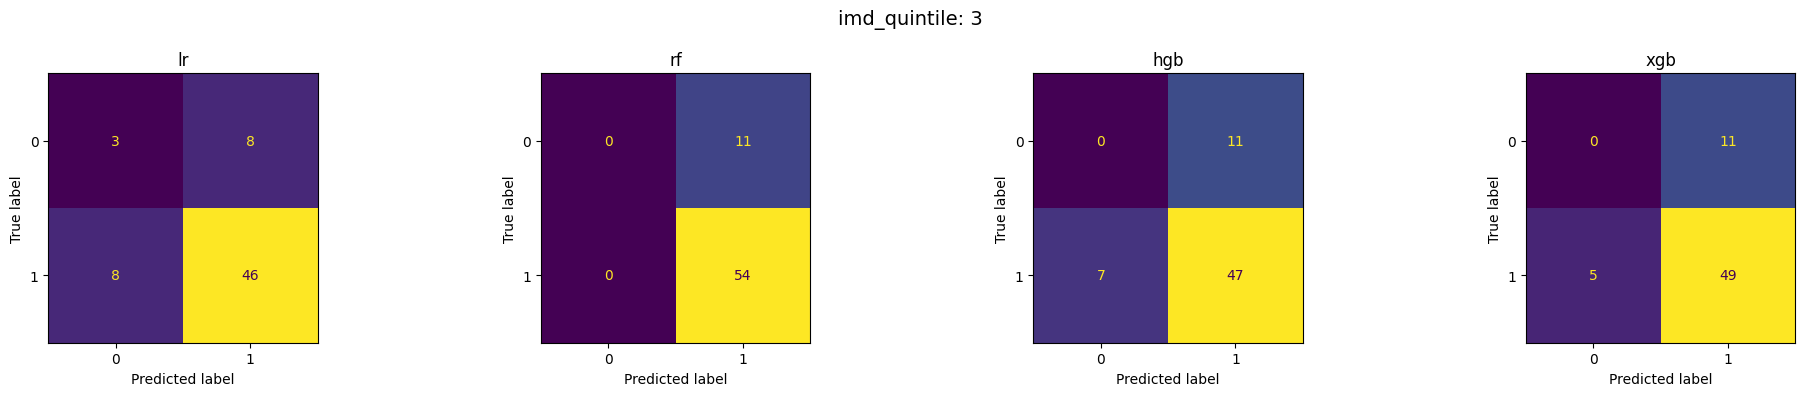

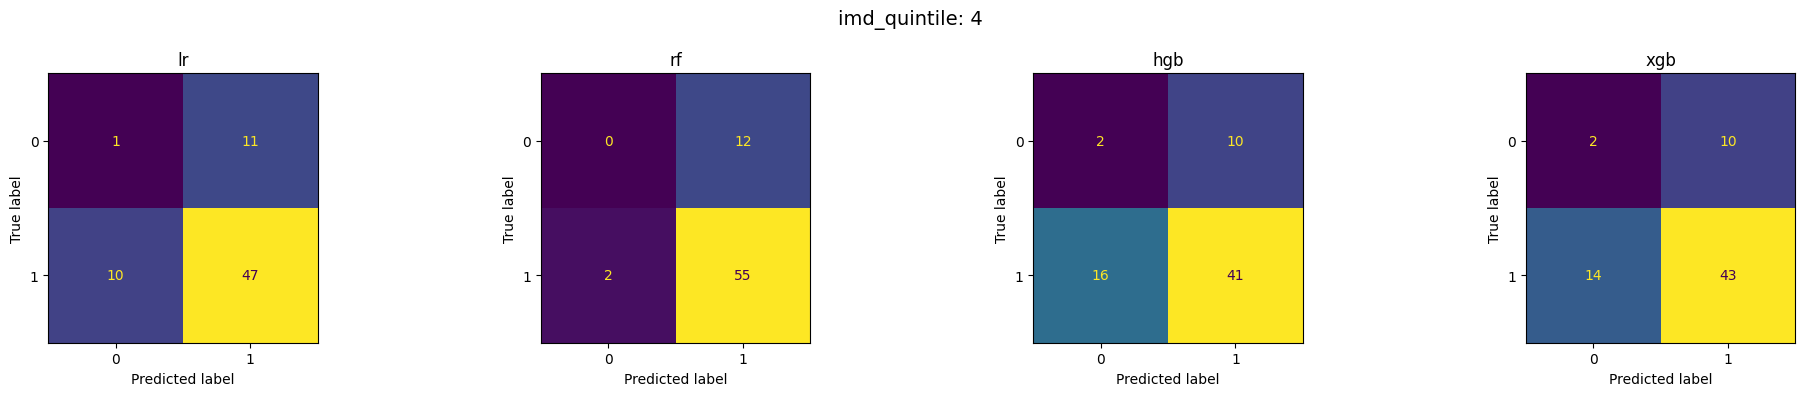

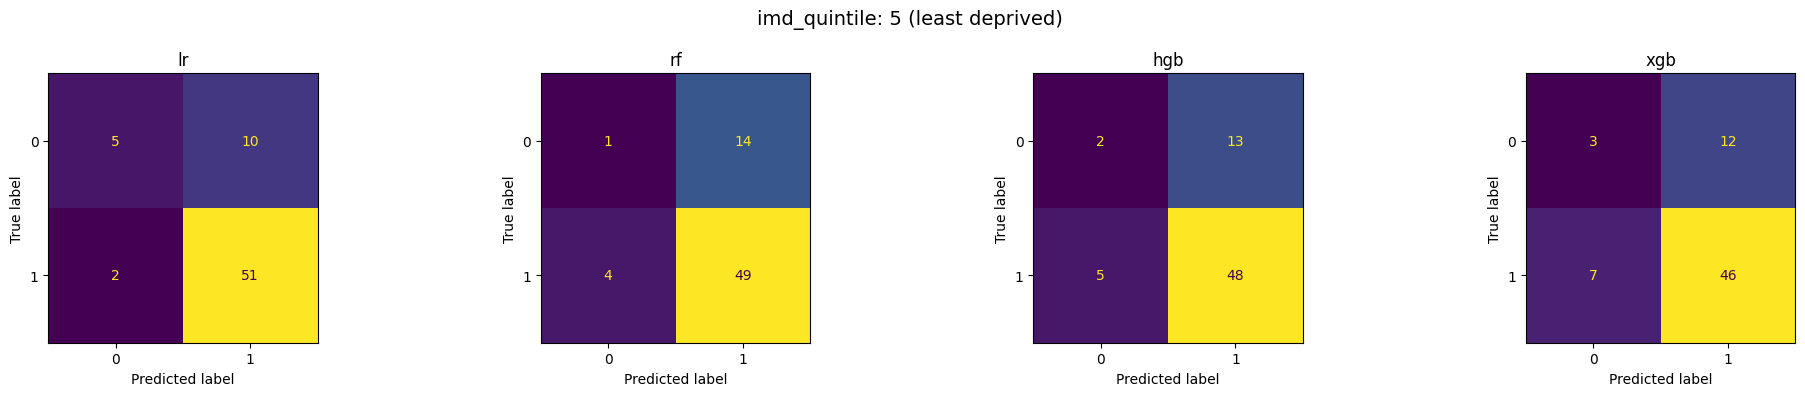

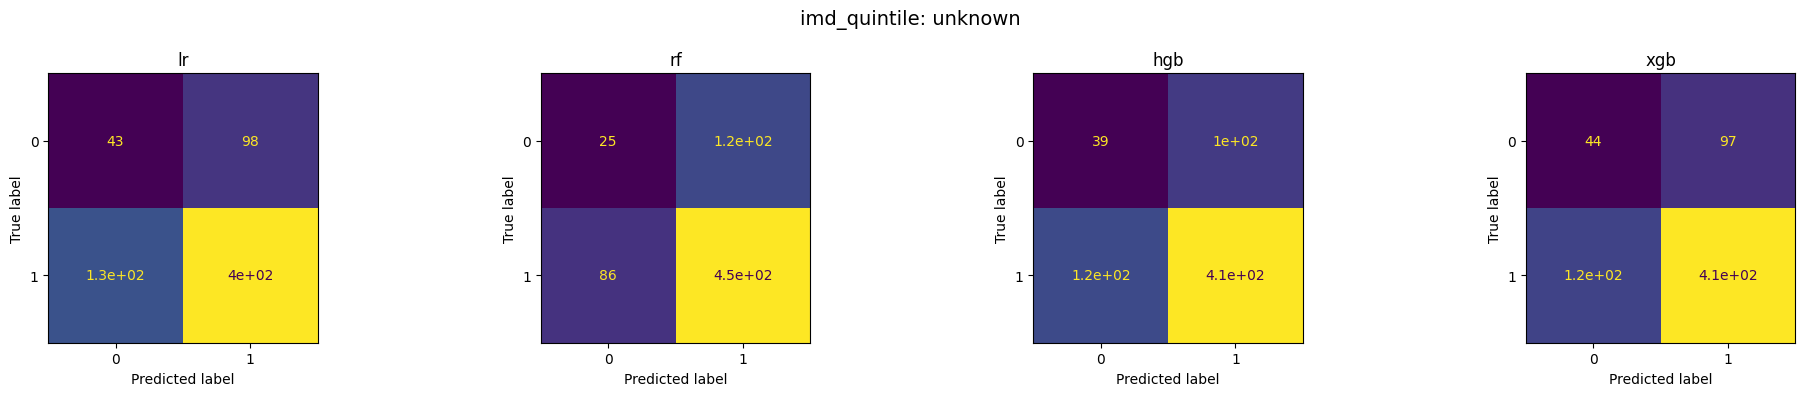

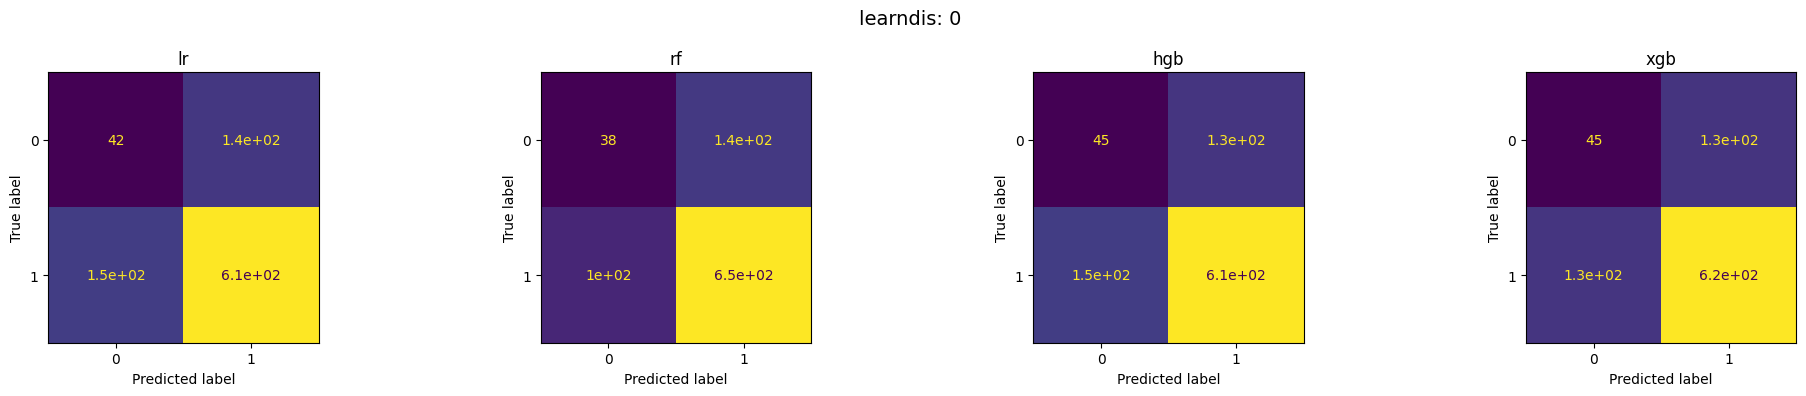

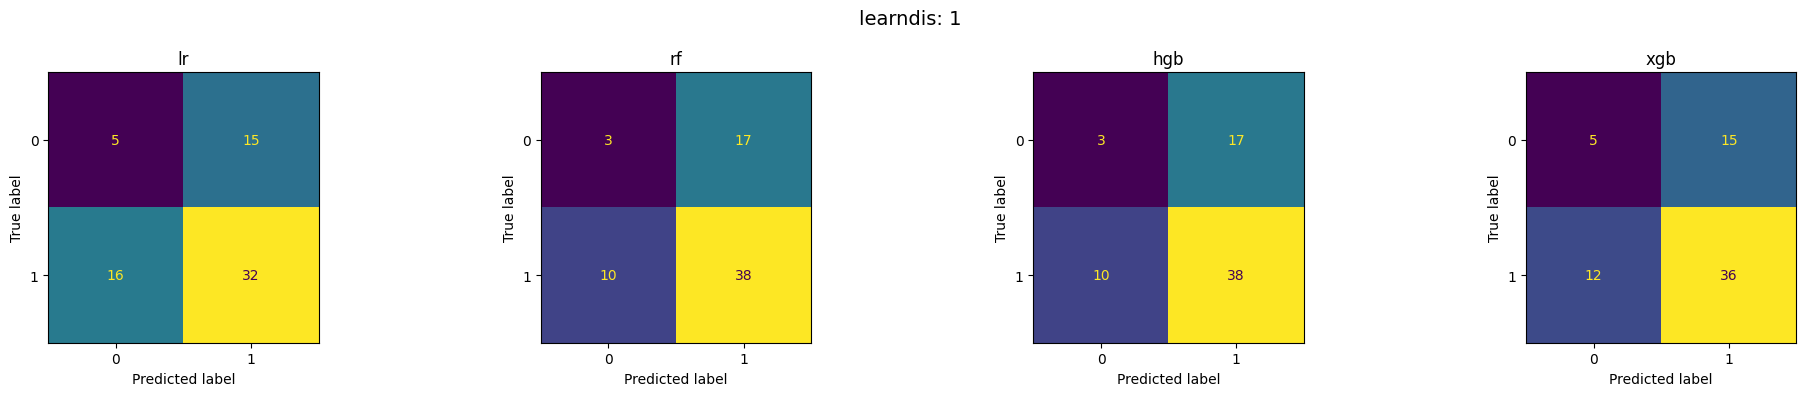

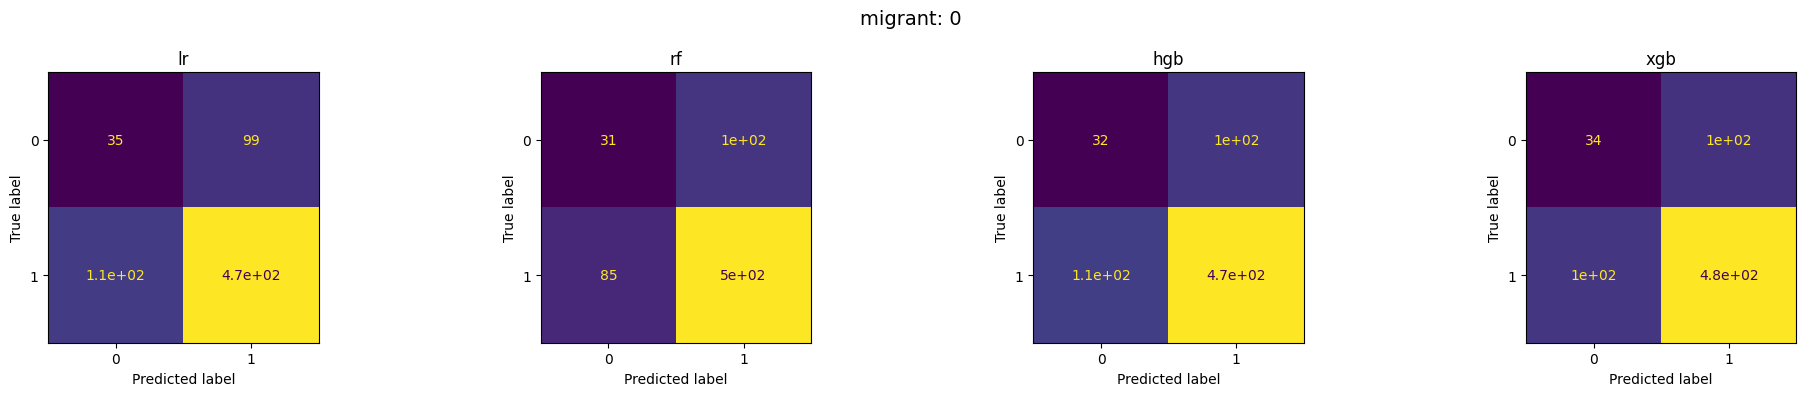

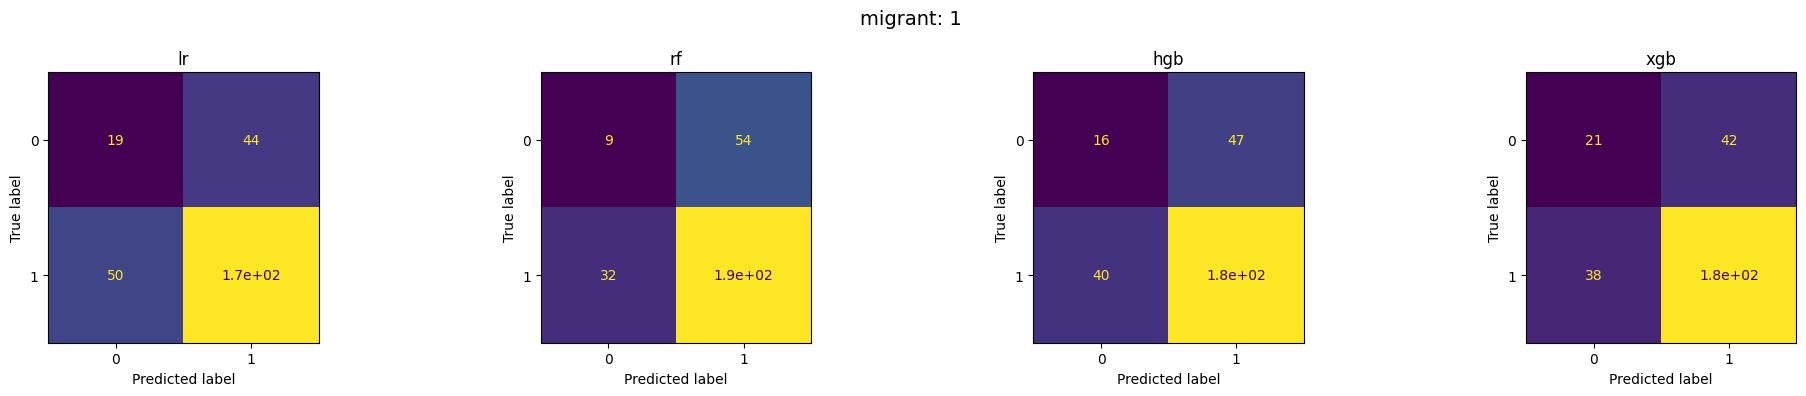

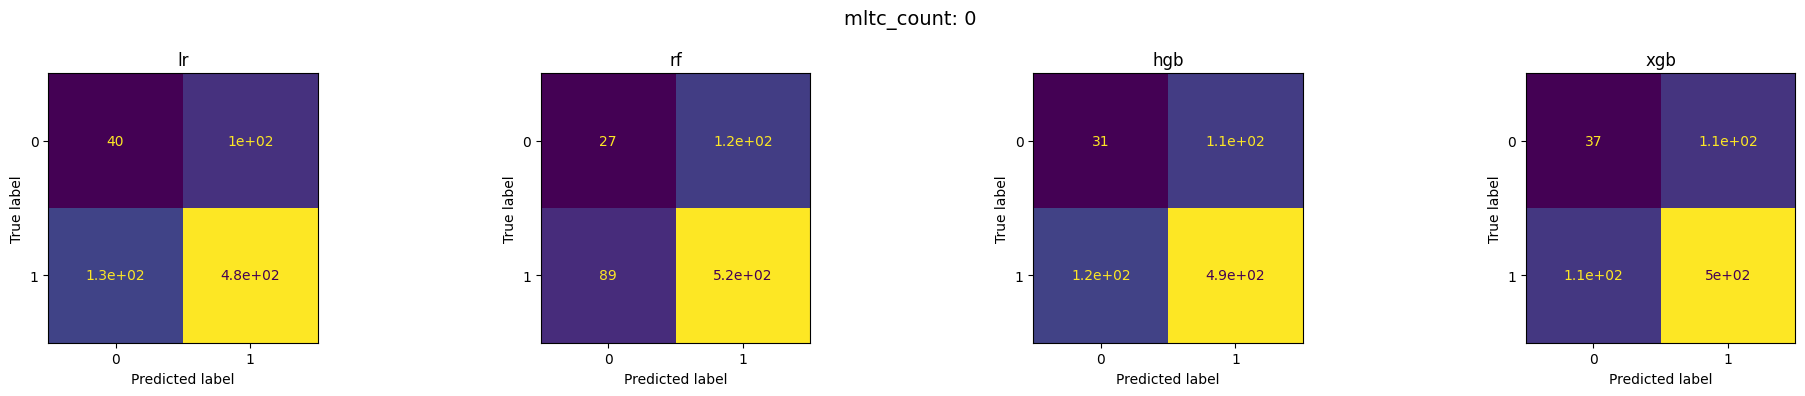

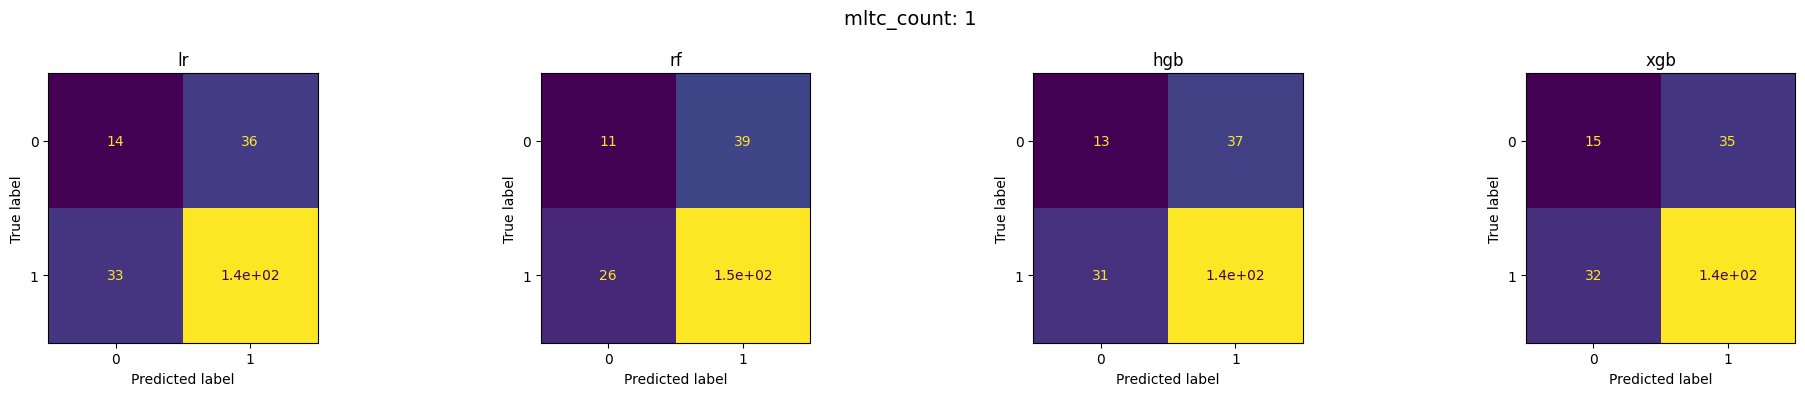

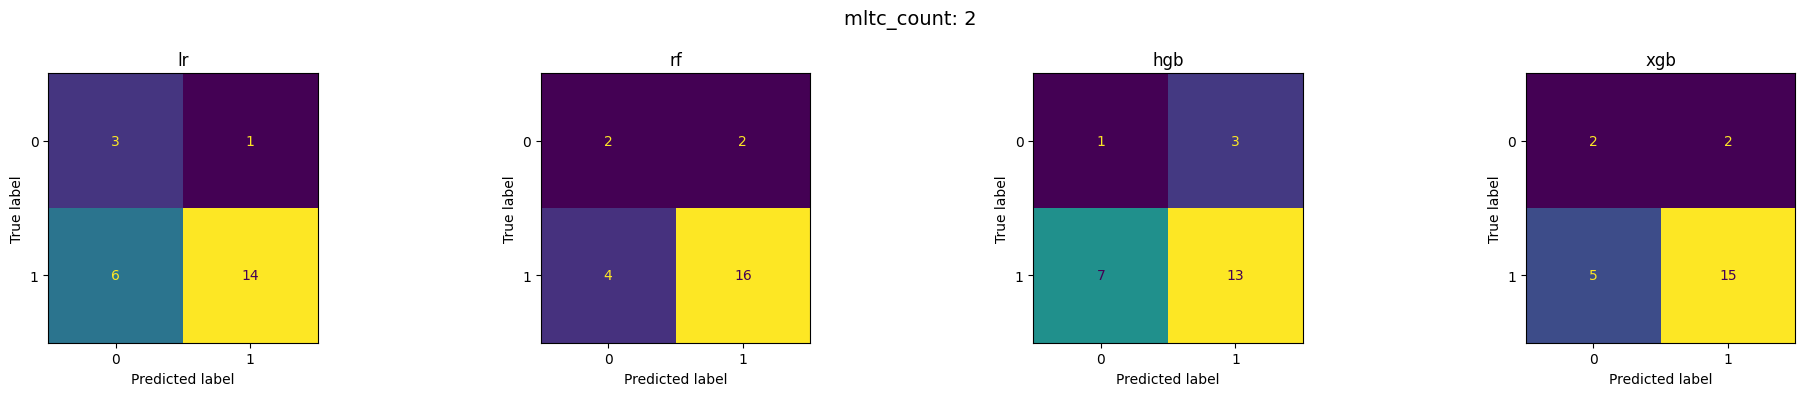

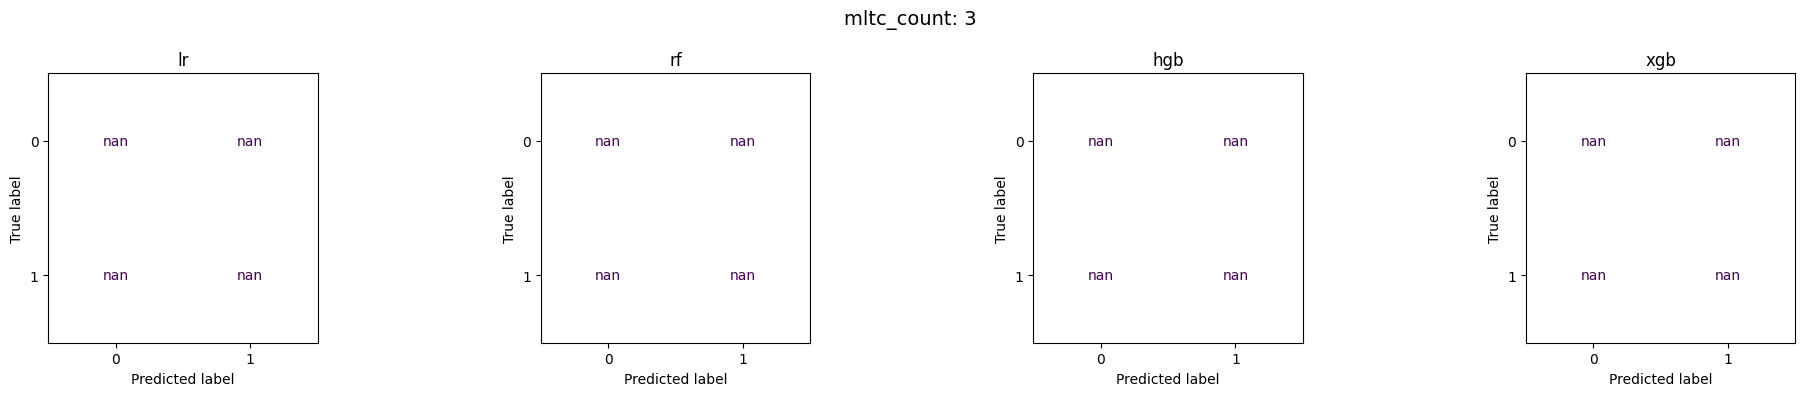

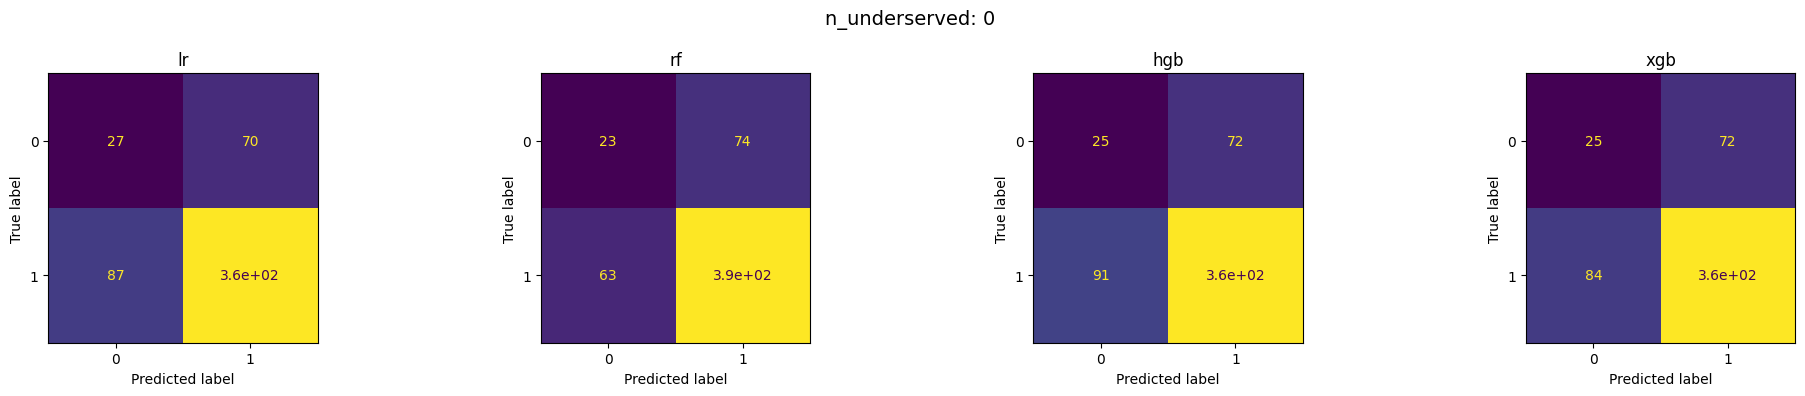

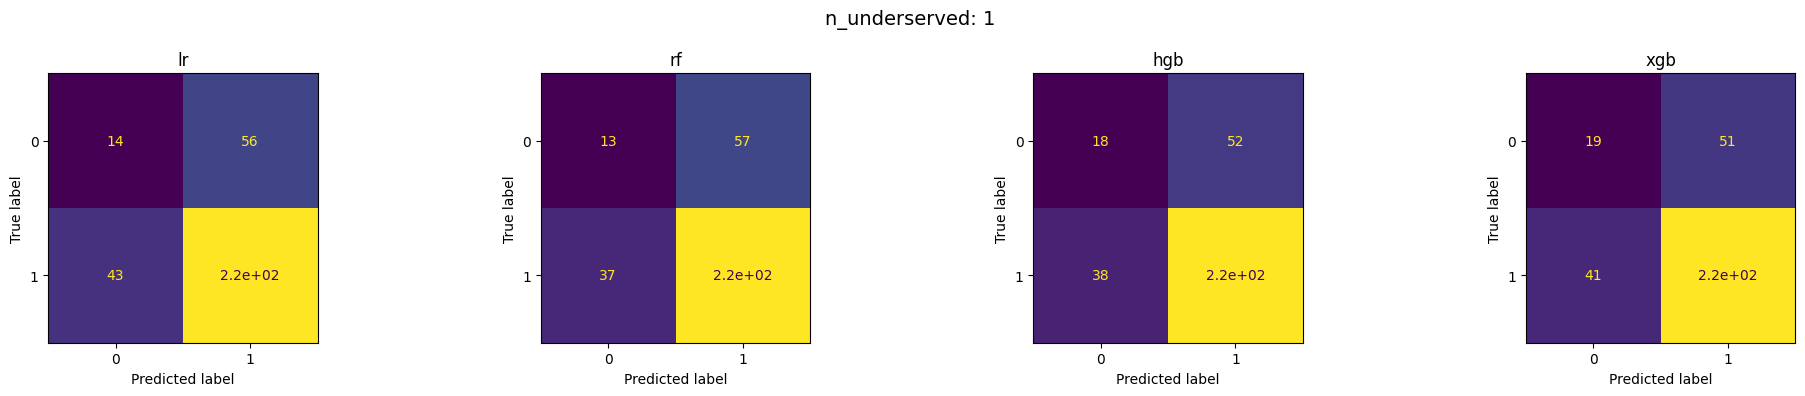

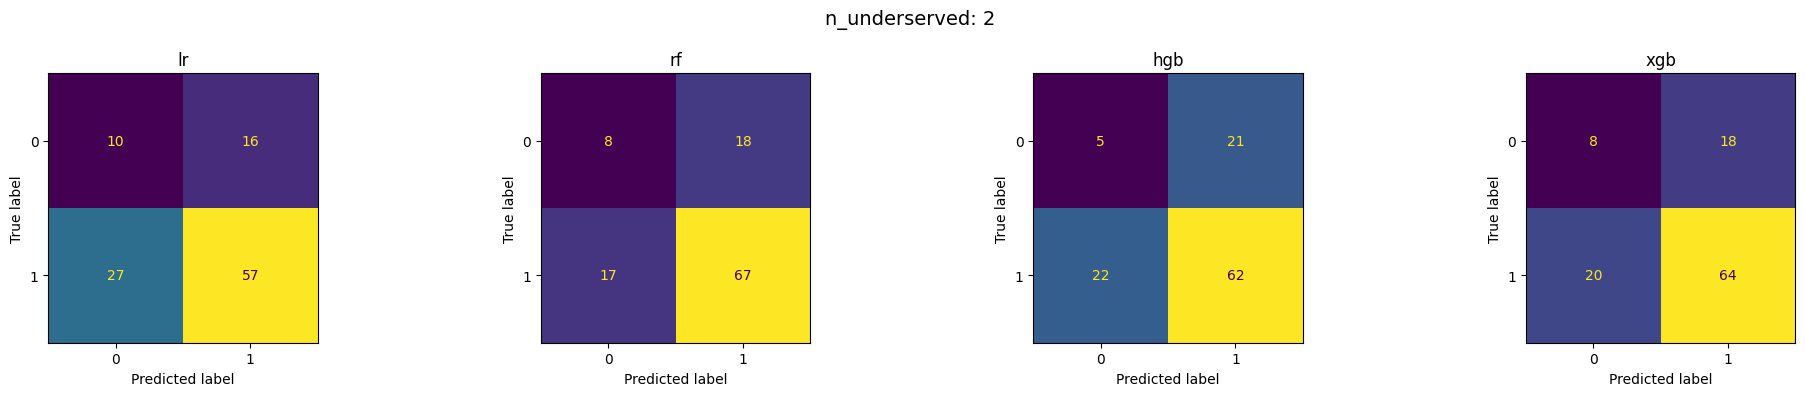

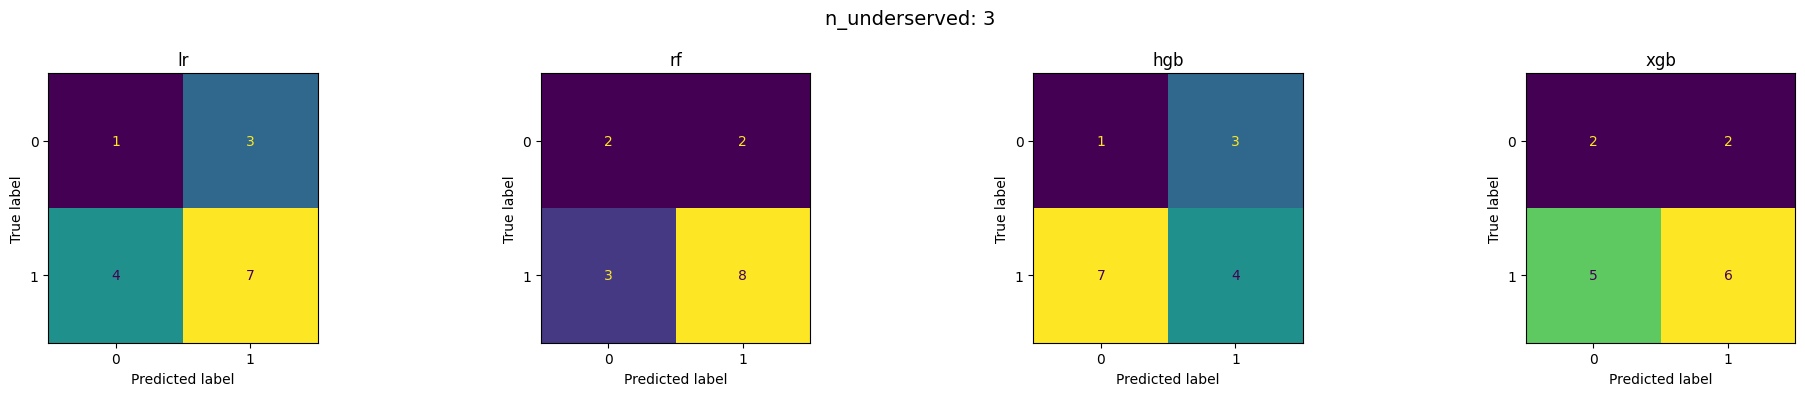

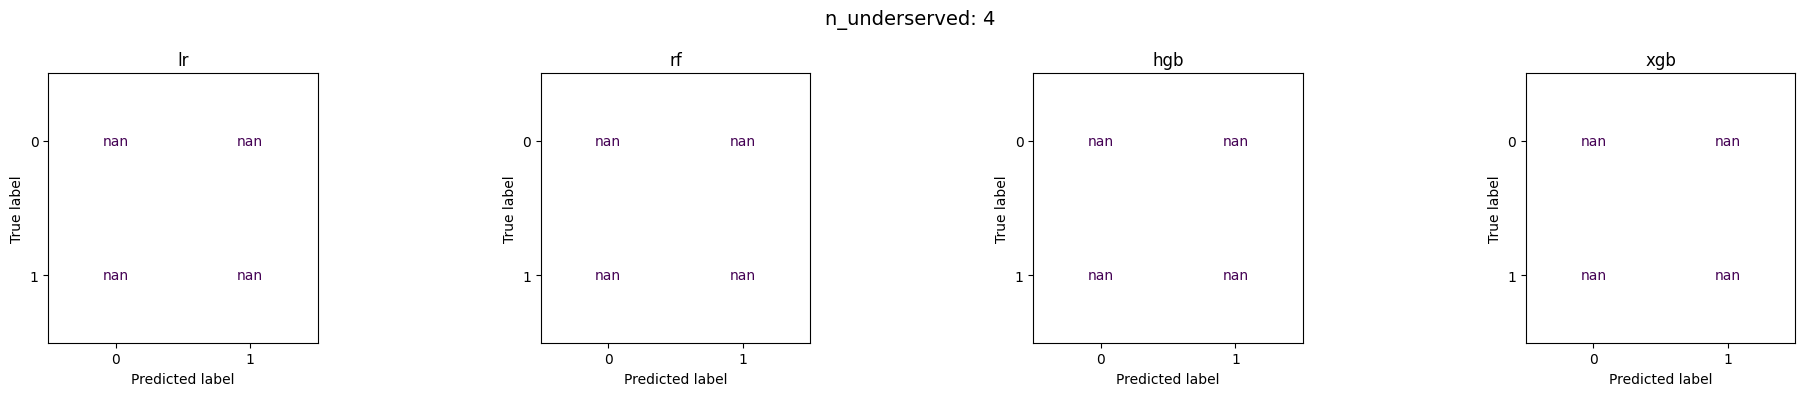

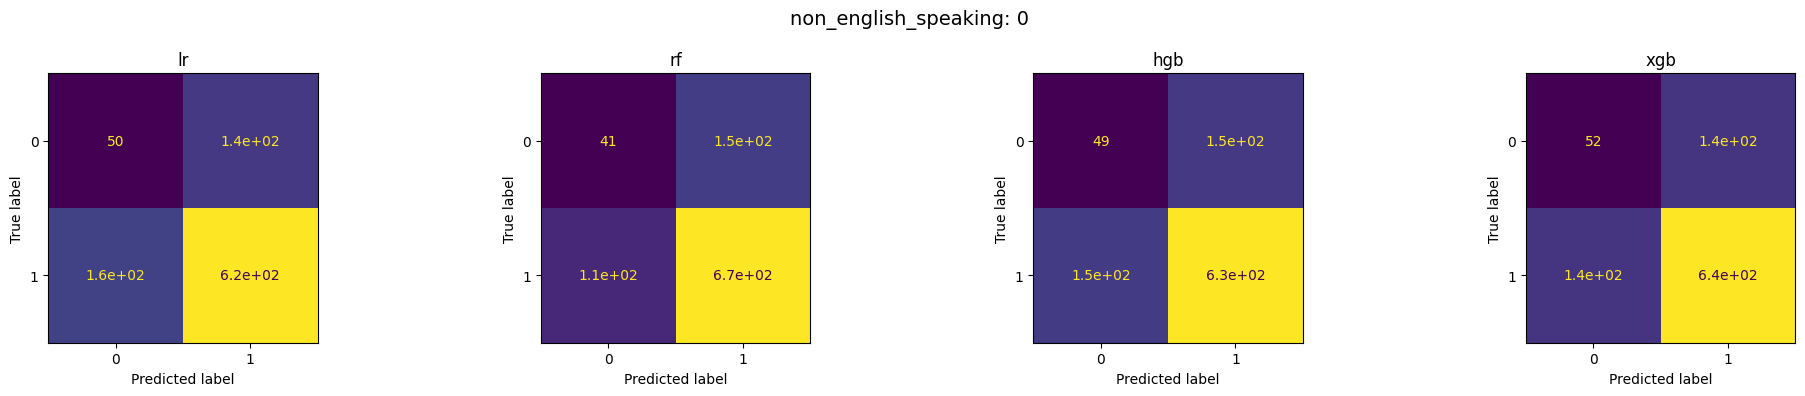

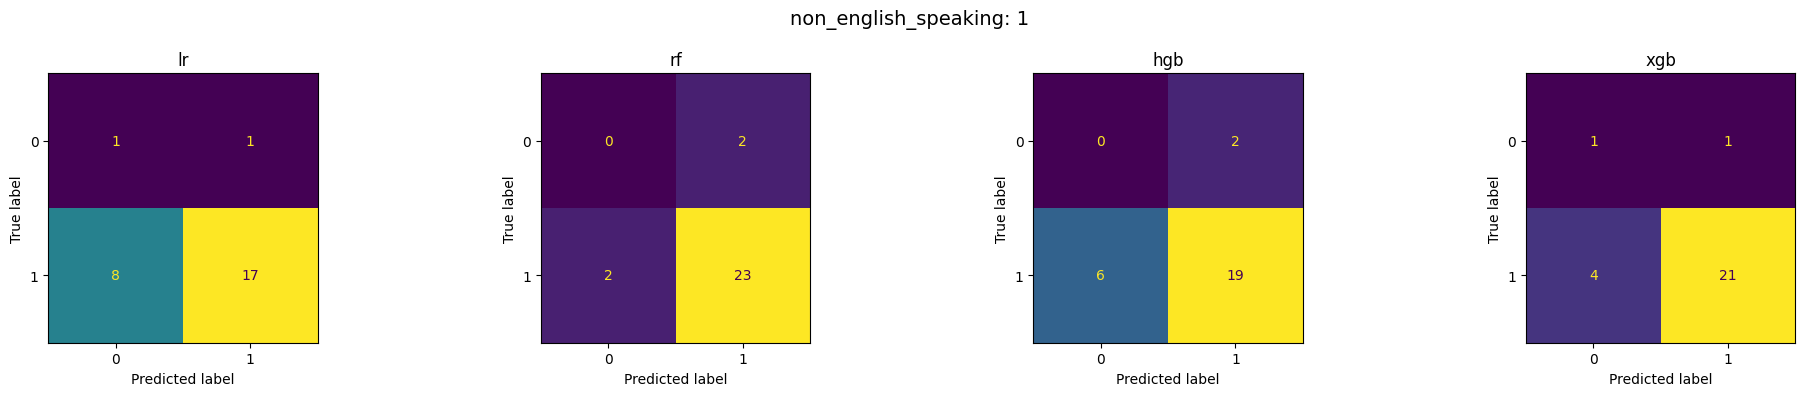

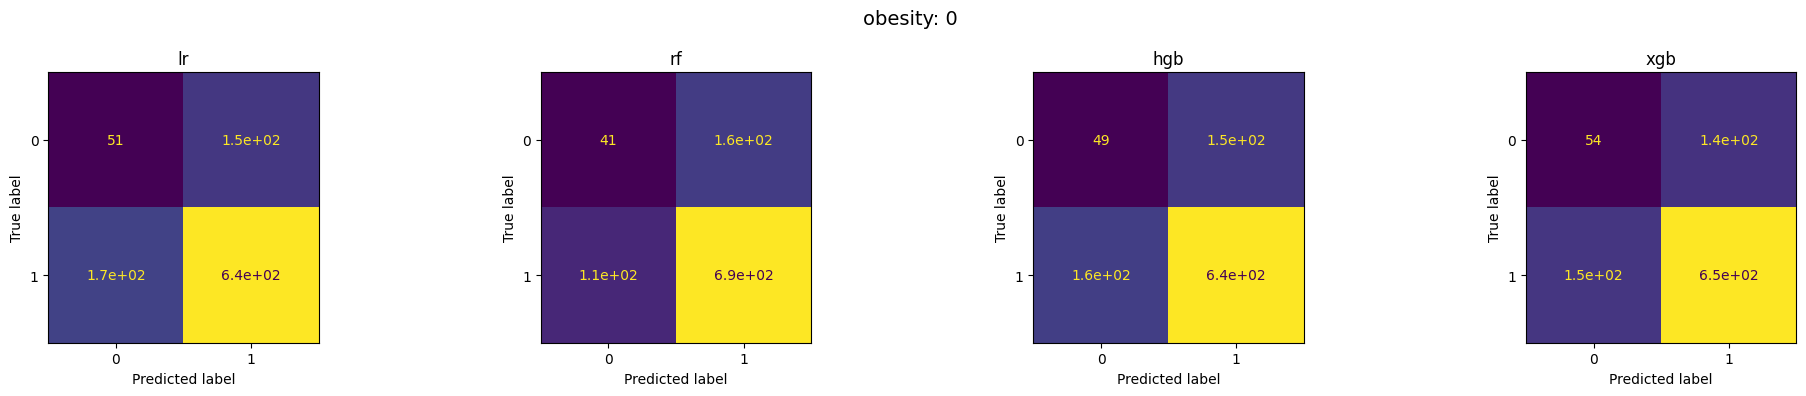

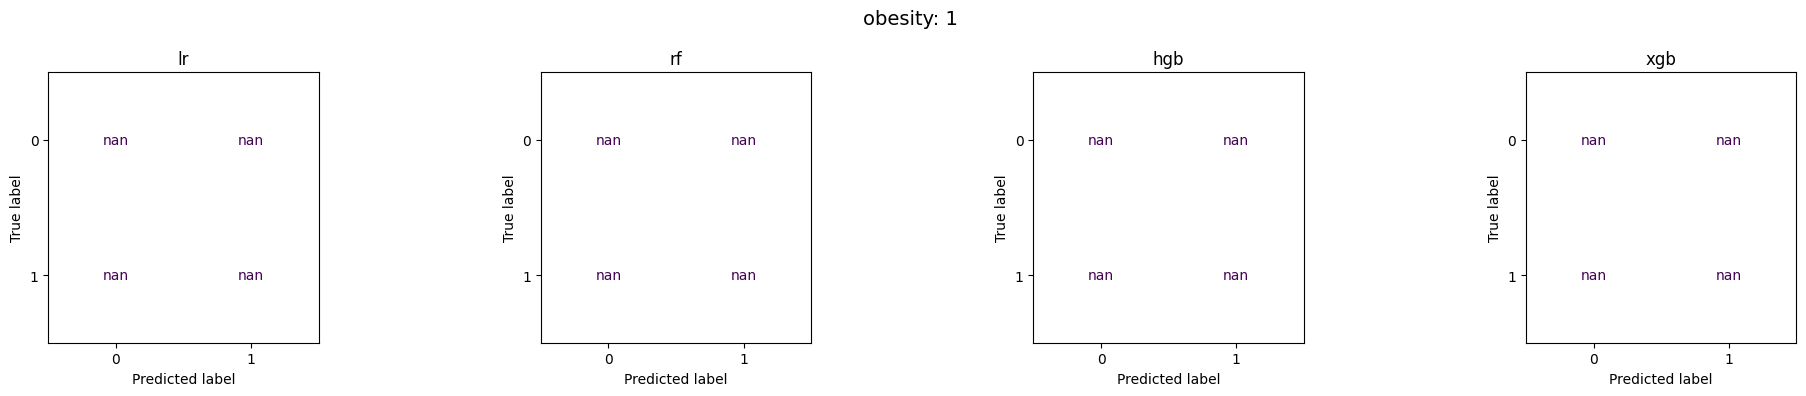

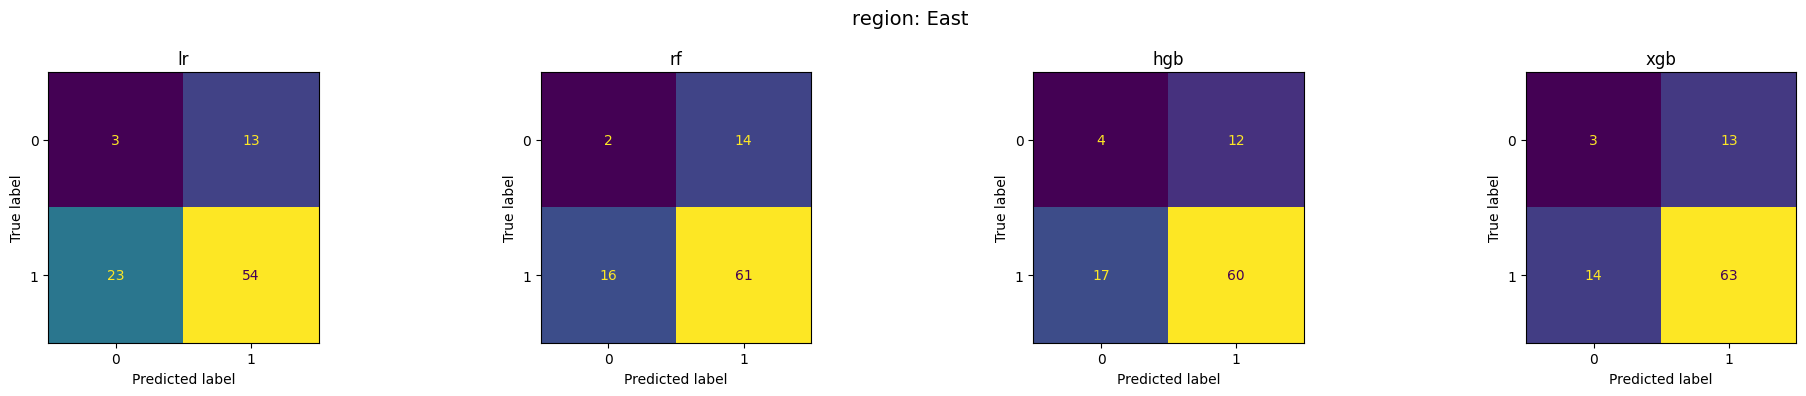

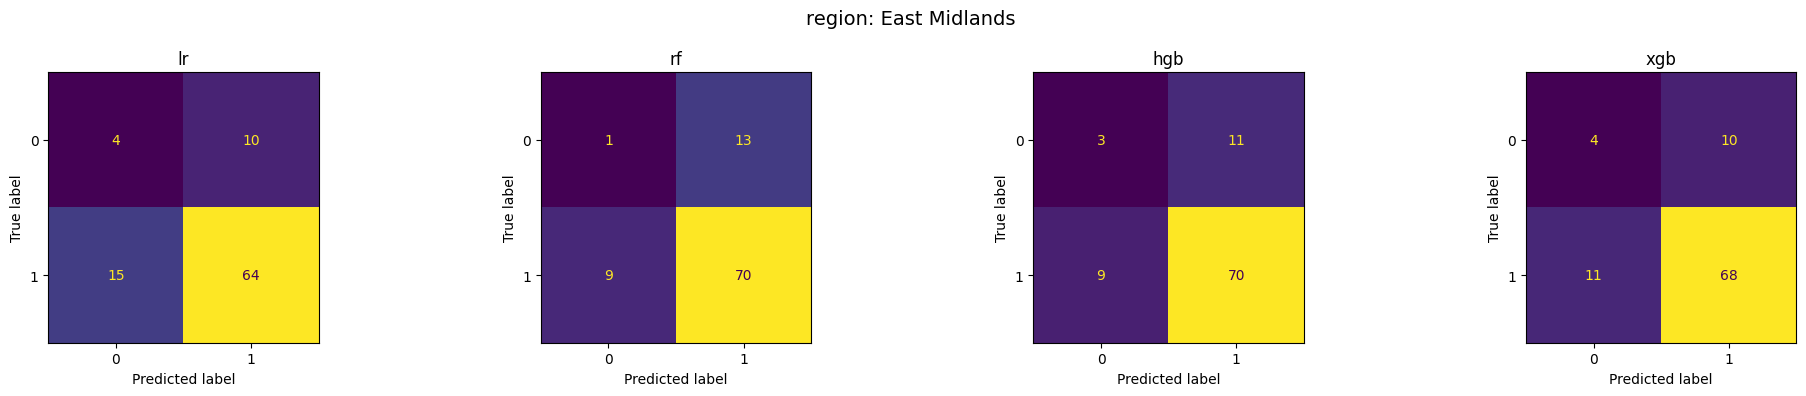

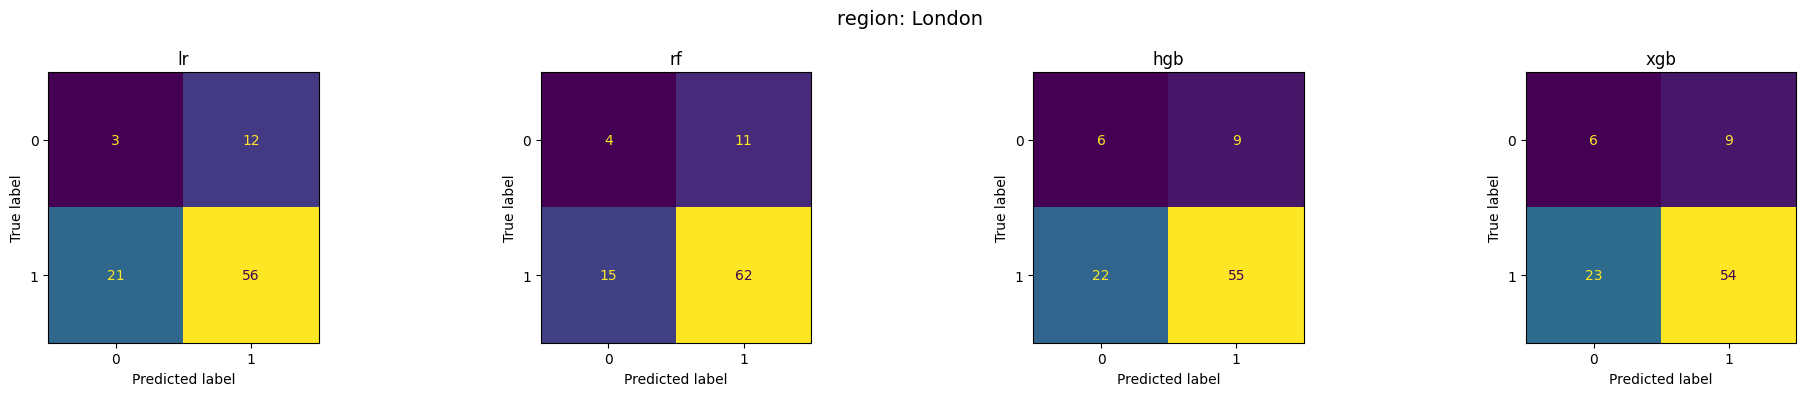

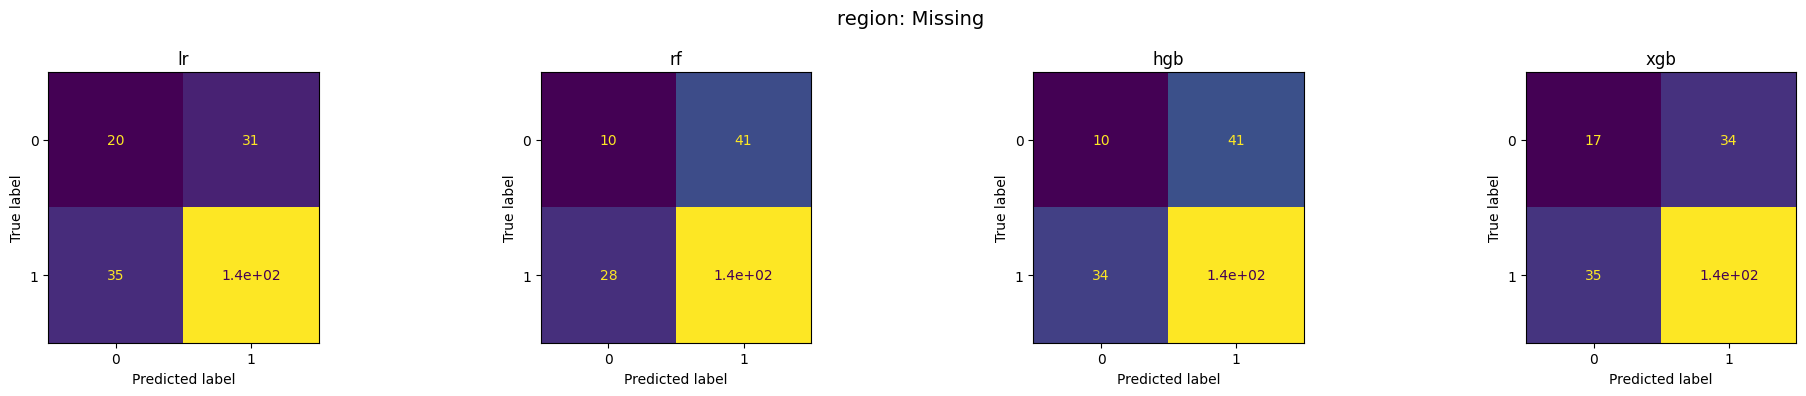

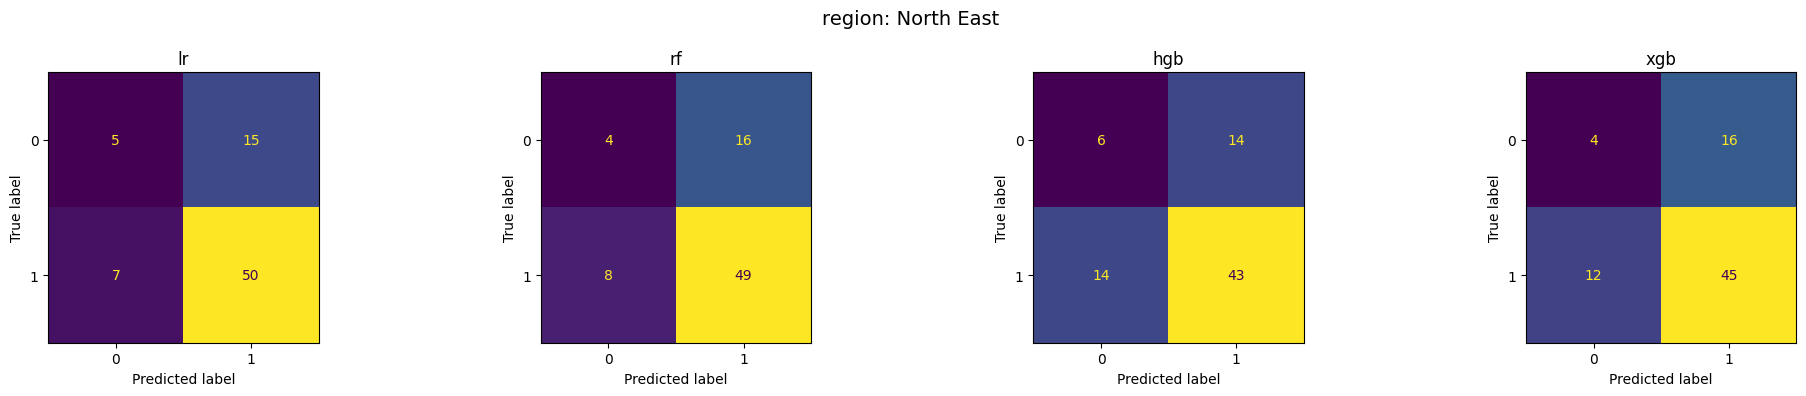

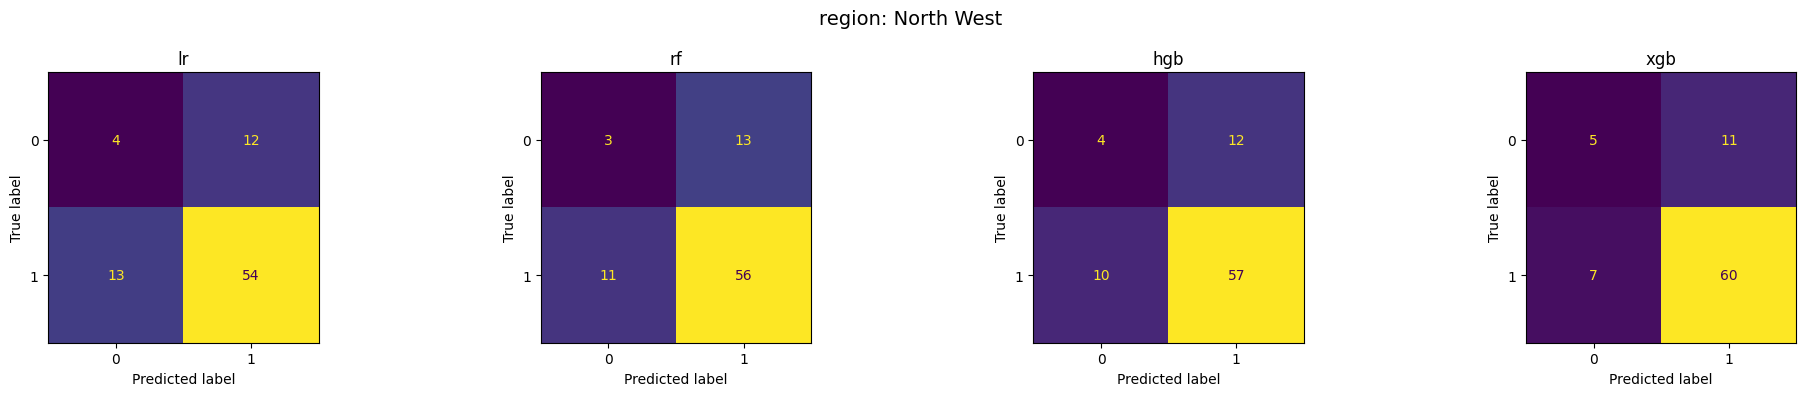

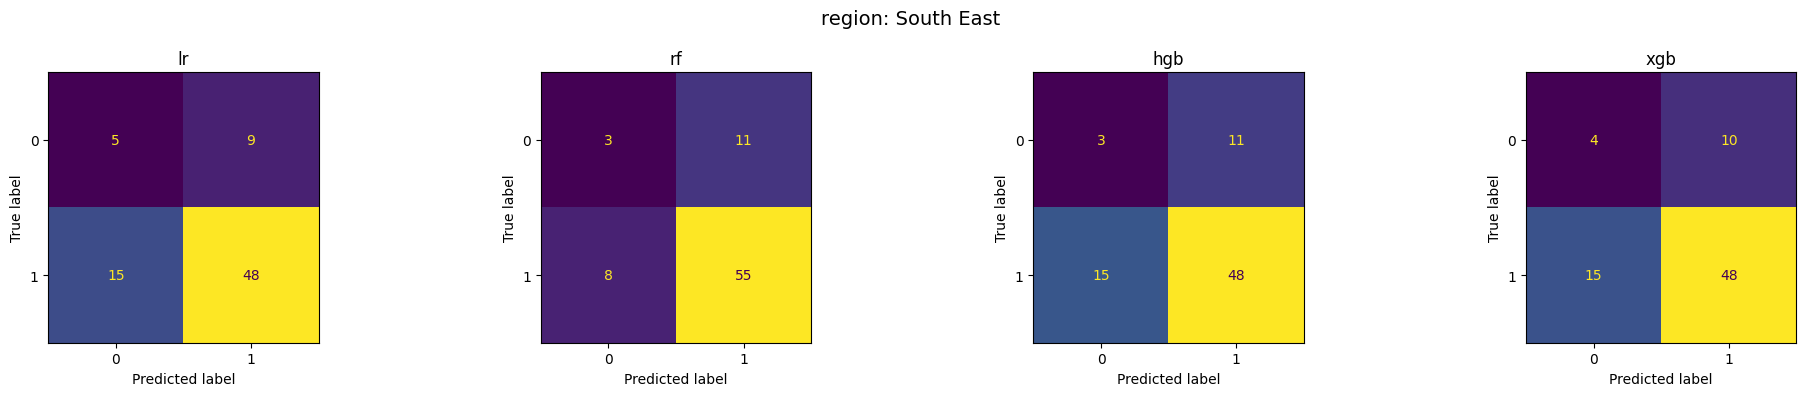

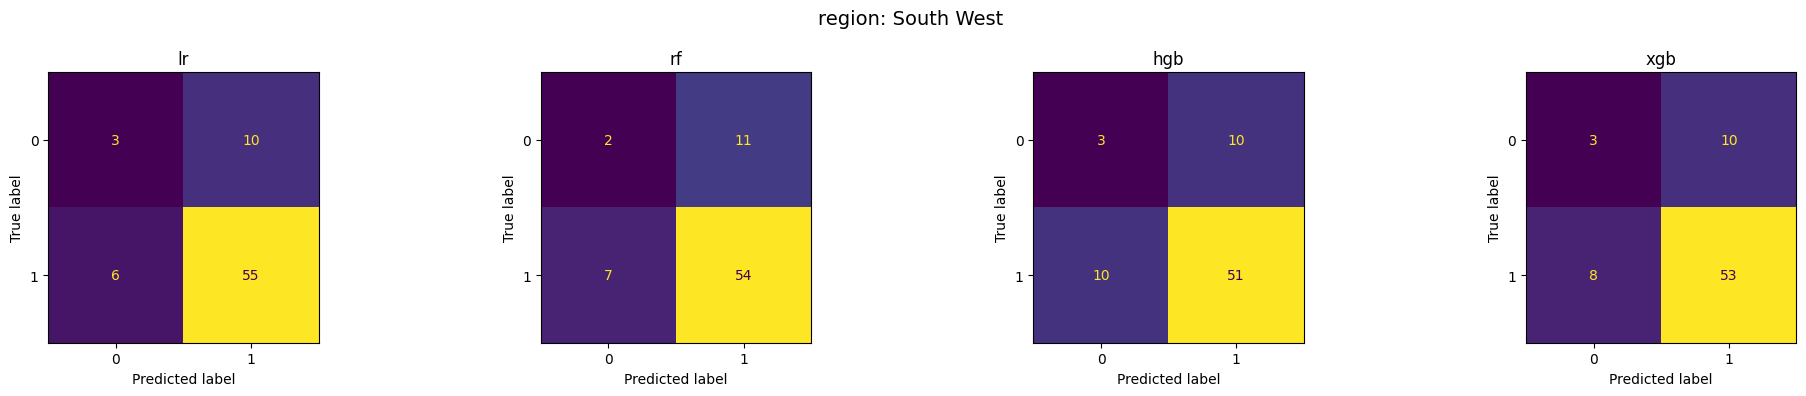

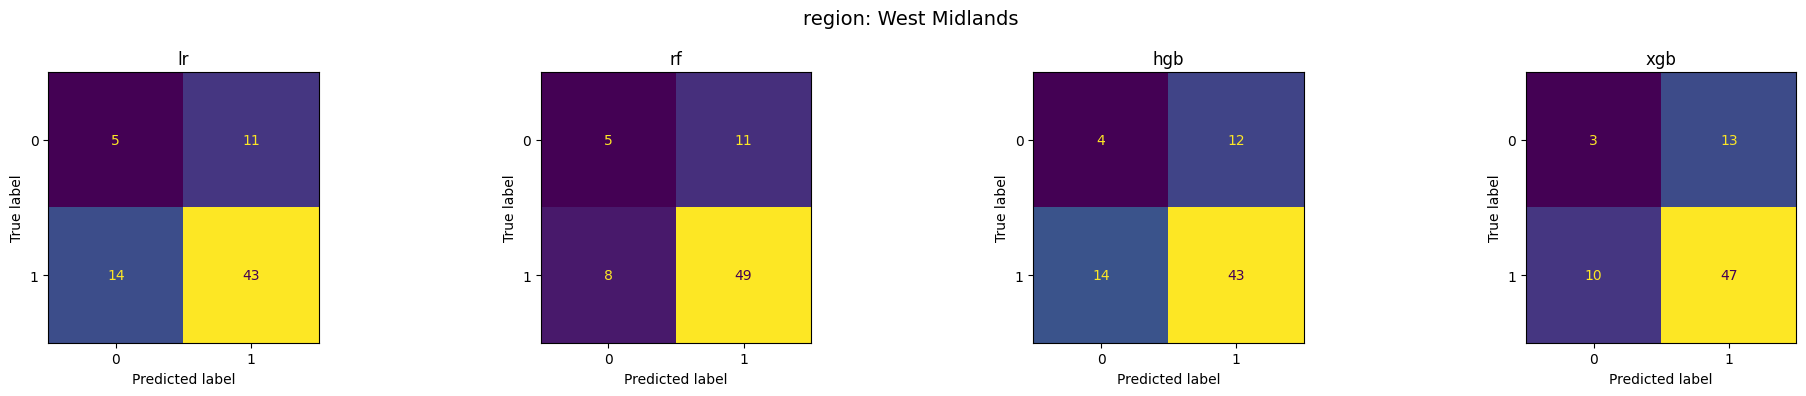

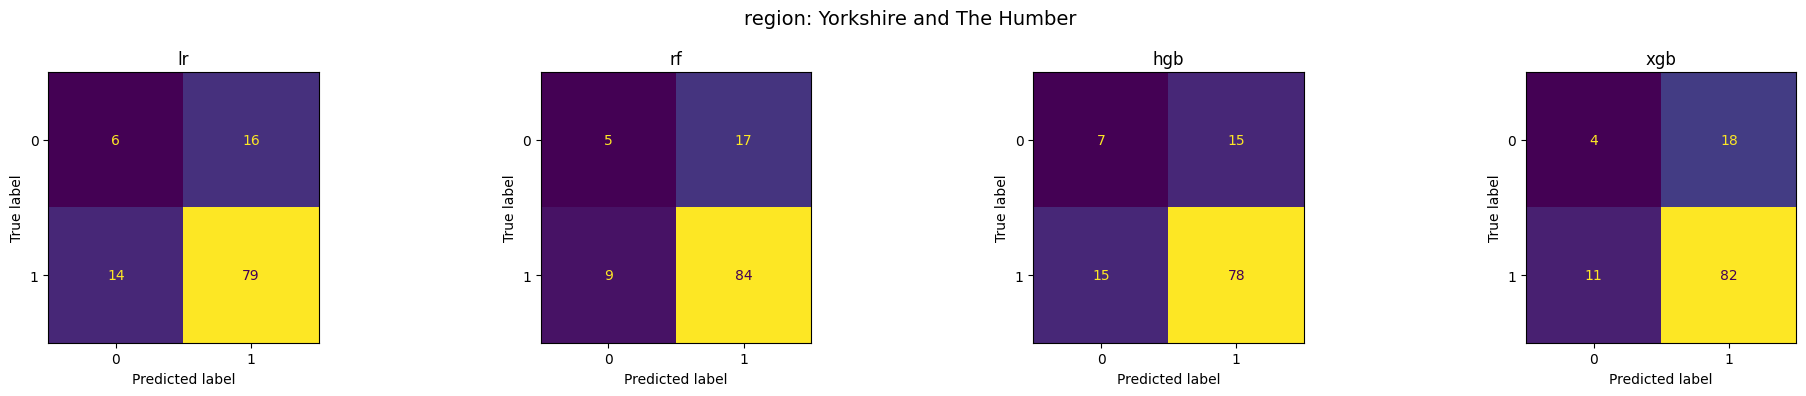

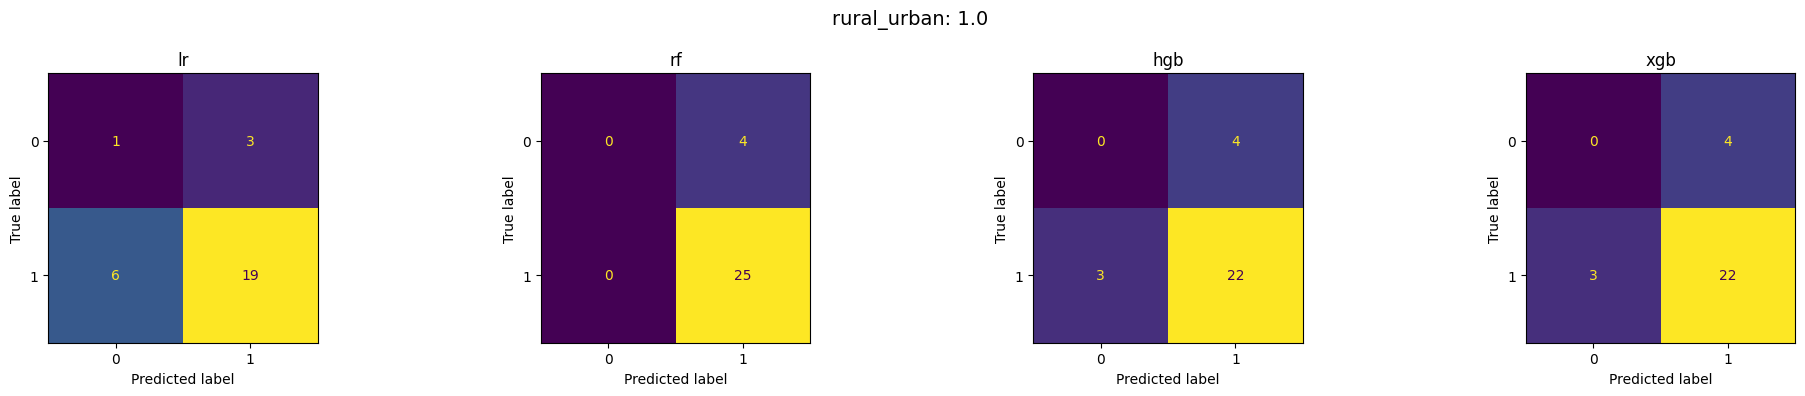

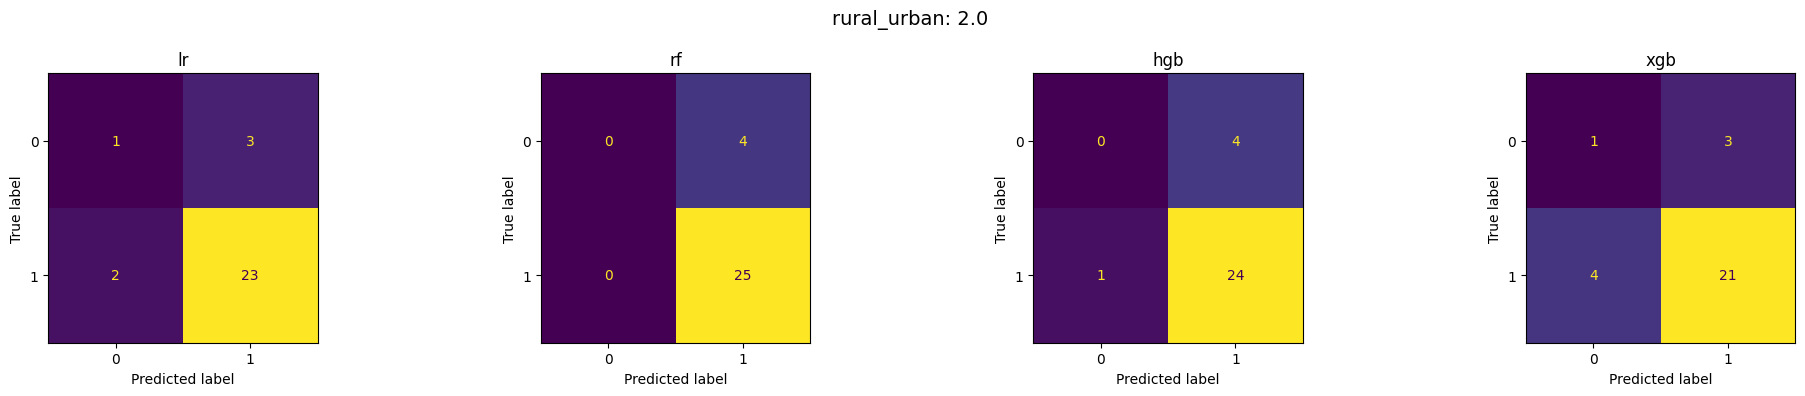

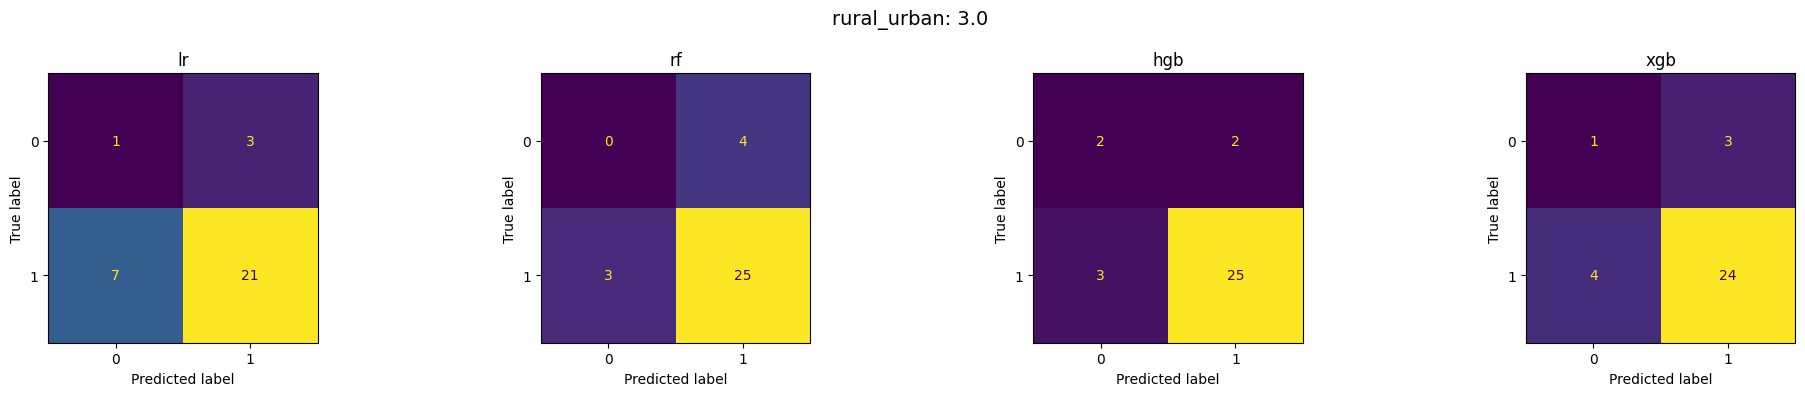

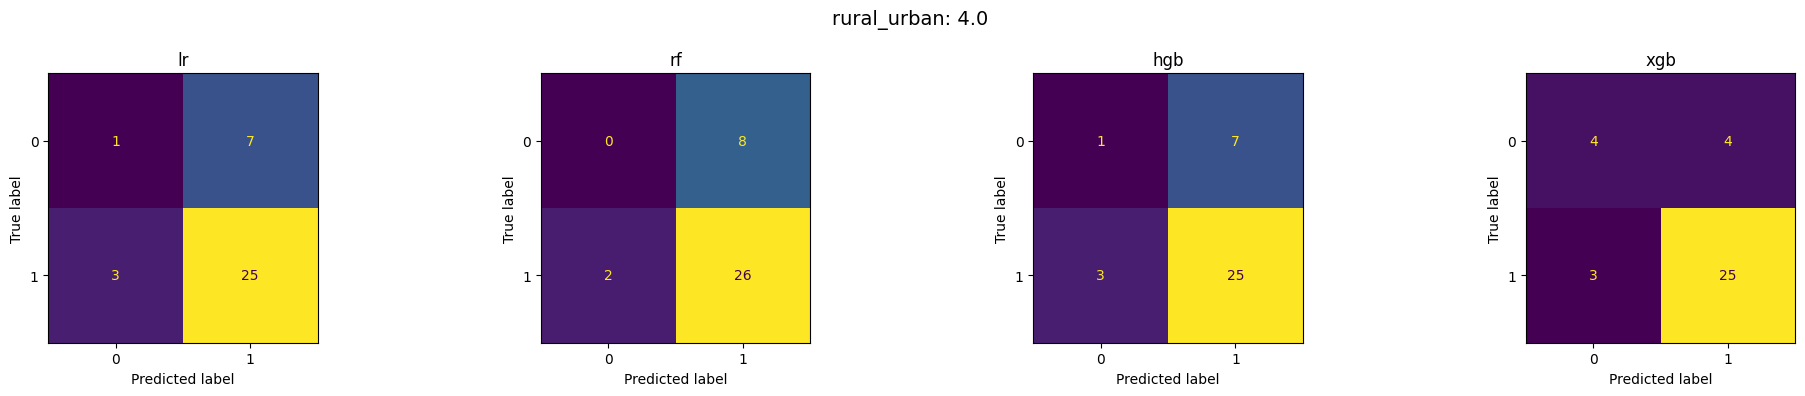

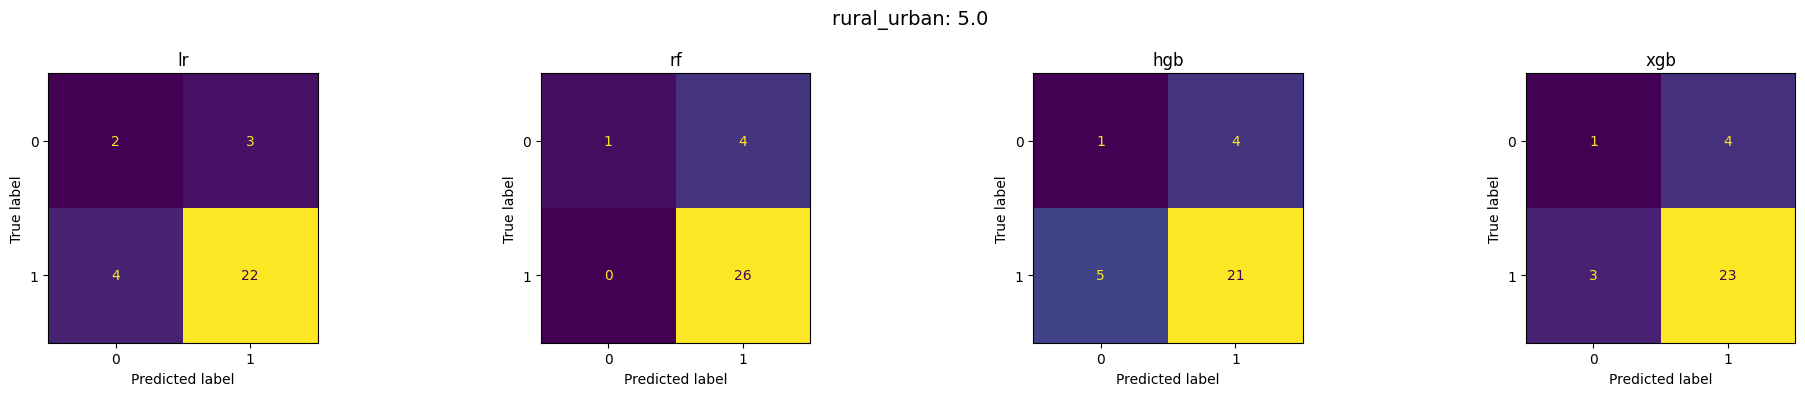

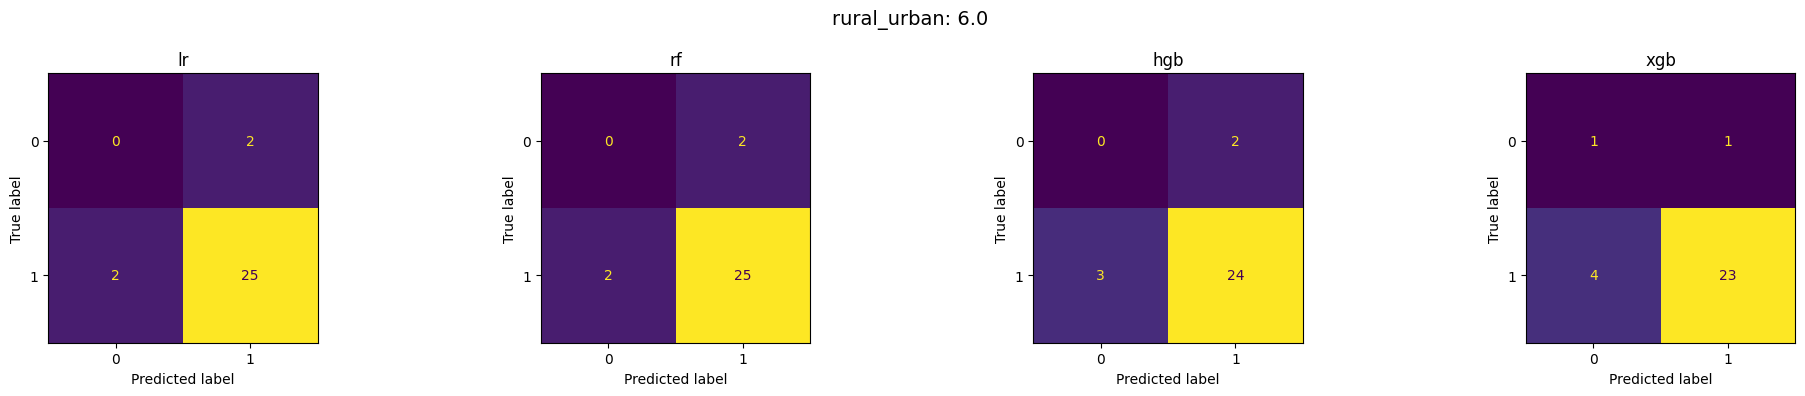

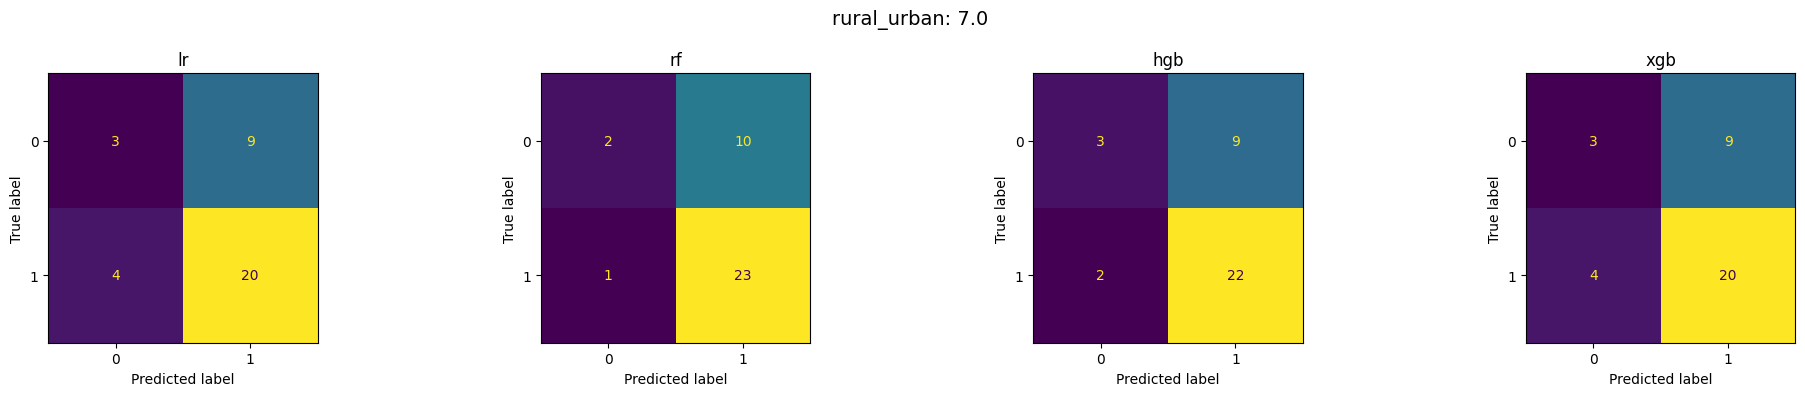

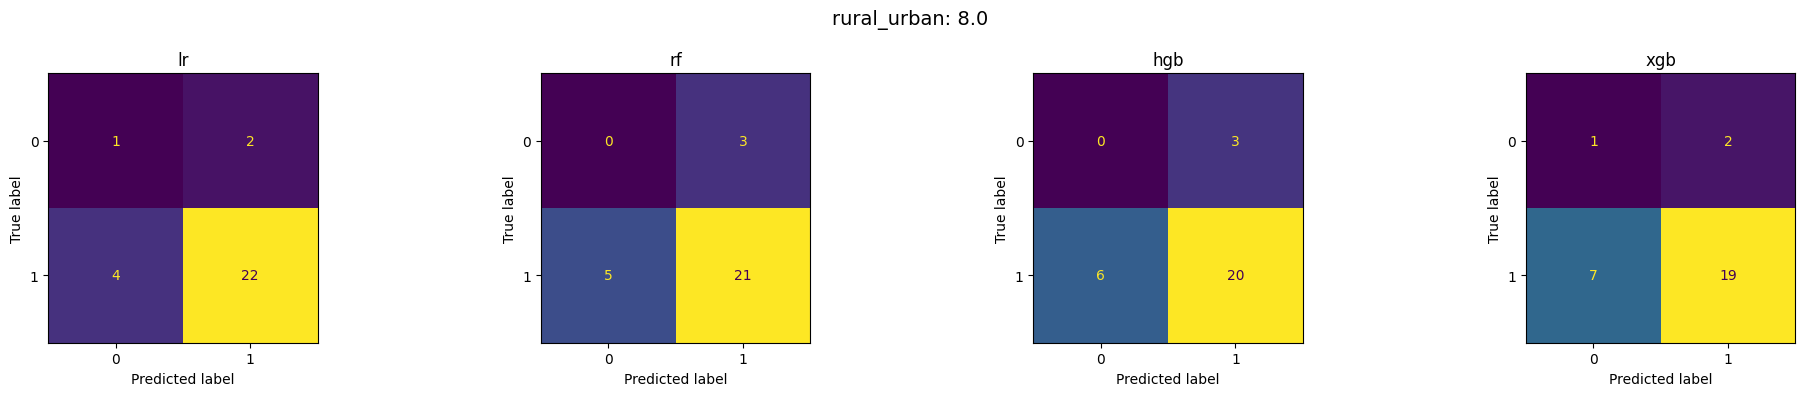

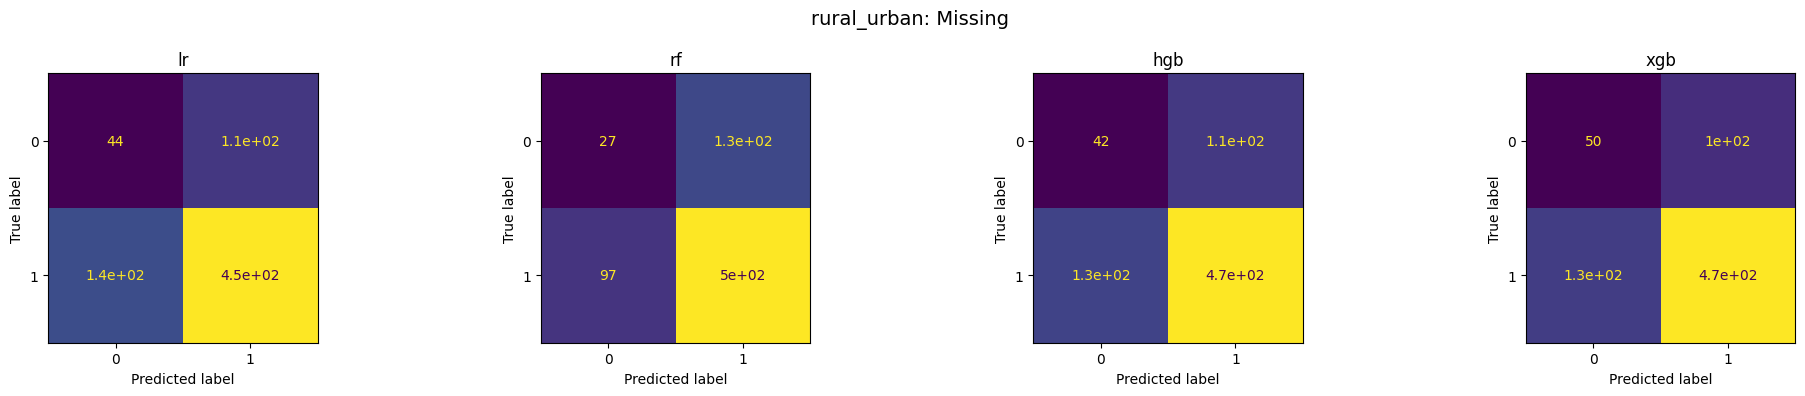

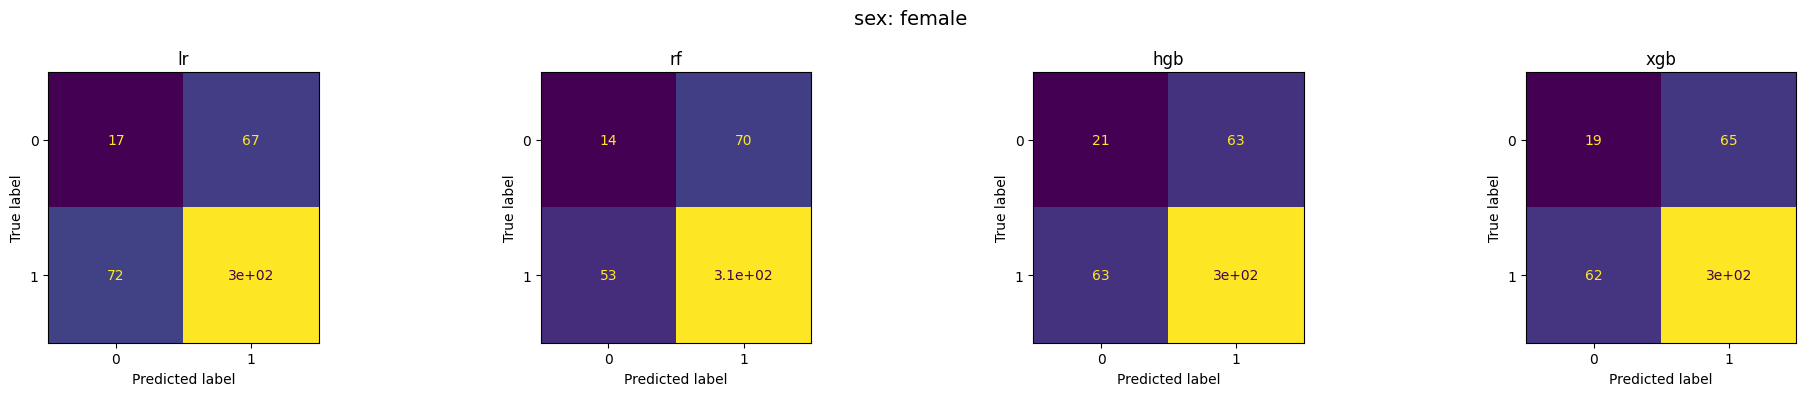

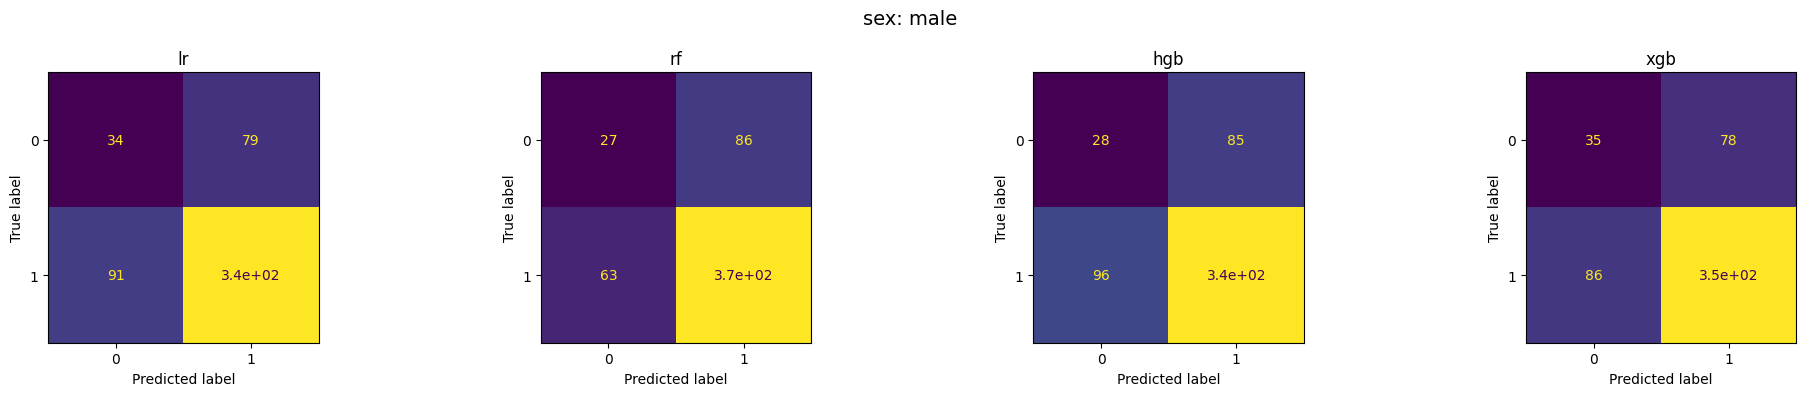

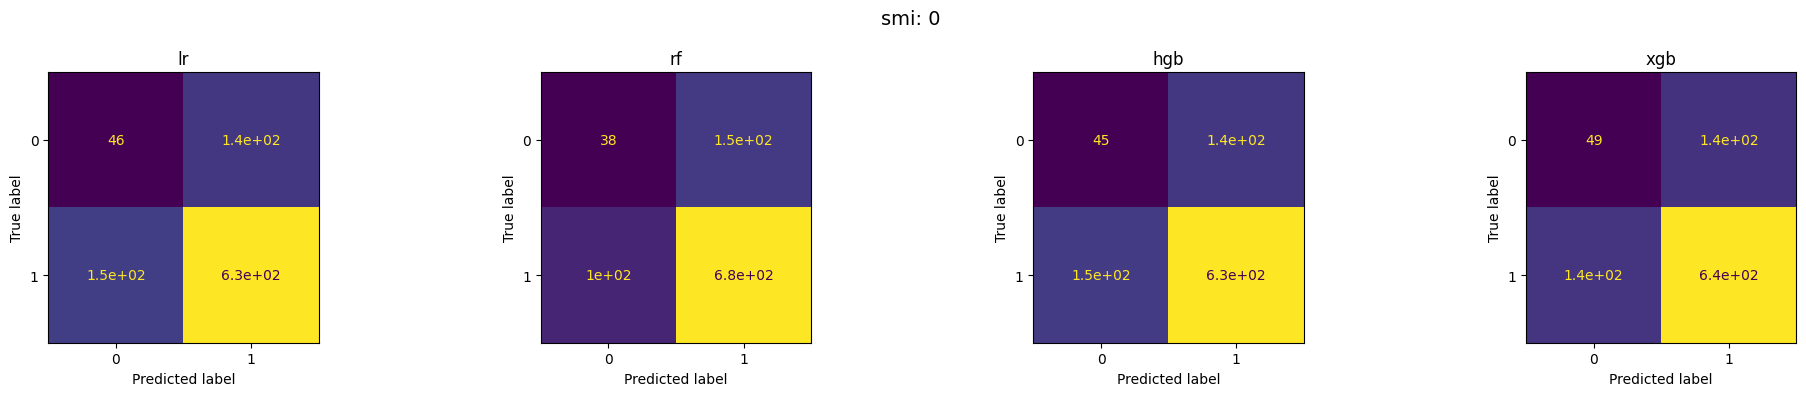

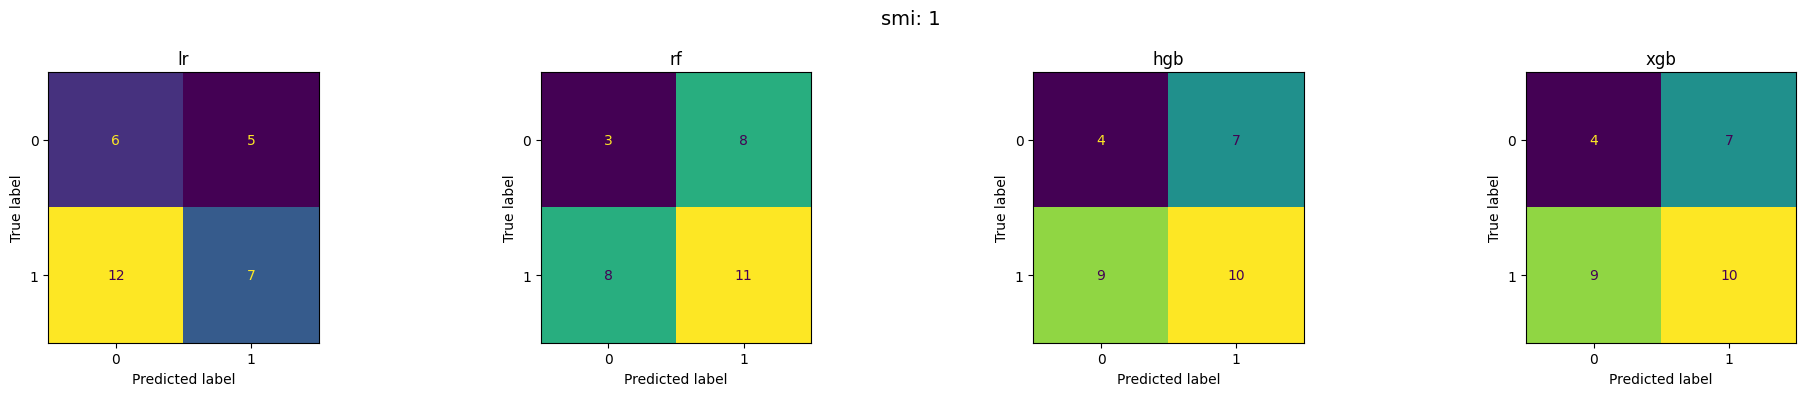

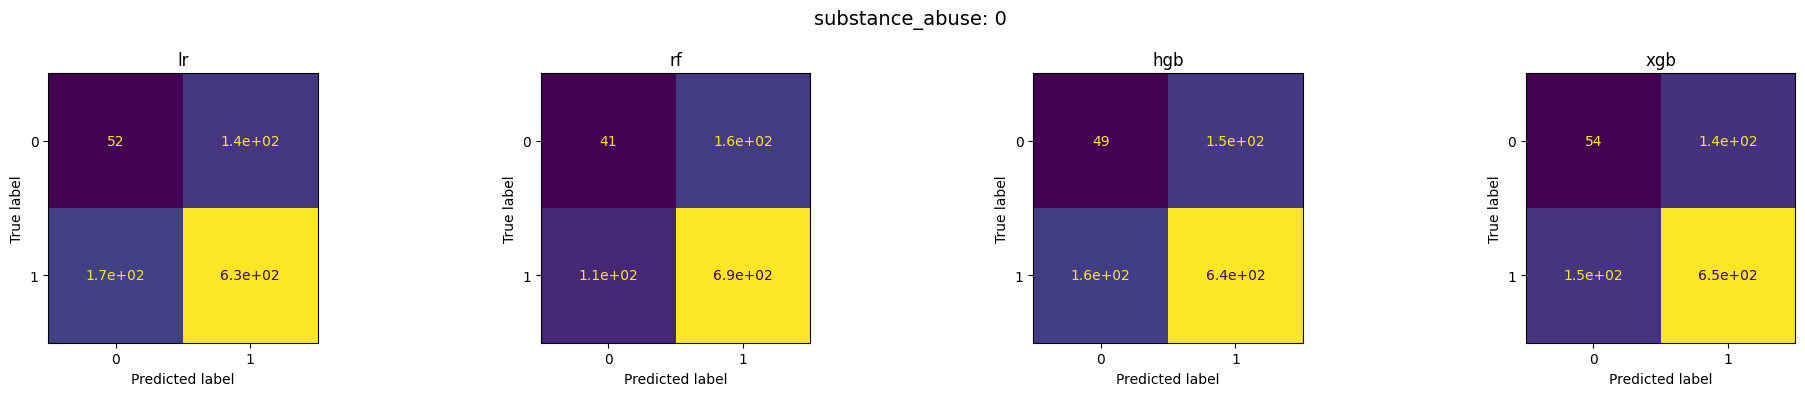

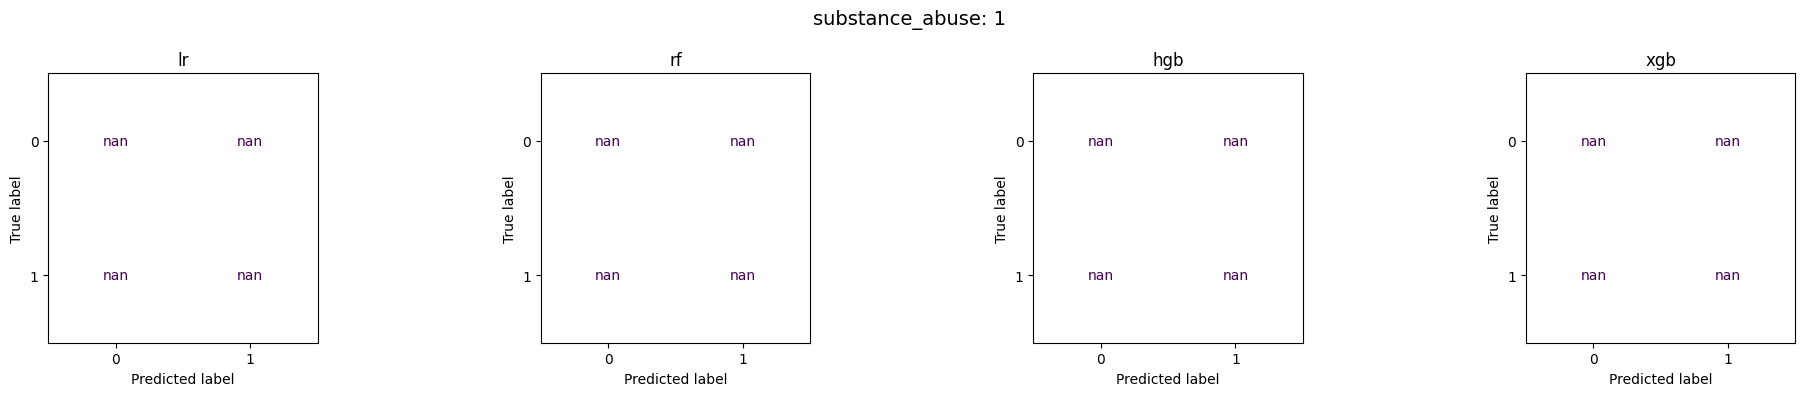

In [12]:
plot_confusion_matrices(
    subgroup_performance_df,
    OPTIMISATION_DIR,
    OPTIMISATION_METHOD,
)